# ДЗ 7. Подбор гиперпараметров и ансамблирование

Работа с датасетом отзывов «Перекрёсток».

1. **Предобработать тексты**: нижний регистр, удаление пунктуации и лишних символов, токенизация, удаление стоп-слов, лемматизация.
2. **Векторизовать тексты**: Bag of Words (BoW) и TF-IDF.
3. **Сравнить представления**: размерность матриц, разреженность, примеры векторов, отличия BoW и TF-IDF.

Помимо базового конвейера ниже подробно разобран **выбор стоп-слов** под задачу тональности: какие служебные слова оставить (отрицания, оценки), какие частотные слова и шаблонные ярлыки формы отзыва убрать. Каждое решение проверено на данных.

## 0. Установка и импорт зависимостей

In [1]:
%pip install datasets pandas numpy matplotlib seaborn pymorphy3 nltk emoji scikit-learn tqdm -q


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import re
from collections import Counter

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)
RANDOM_STATE = 42

In [3]:
# --- Кэш предобработки: не гонять лемматизатор каждый раз ---
from pathlib import Path
PREP_CACHE = Path("perekrestok_preprocessed.parquet")
PREP_READY = False
try:
    if not PREP_CACHE.exists() and PREP_CACHE.with_suffix(".pkl").exists():
        PREP_CACHE = PREP_CACHE.with_suffix(".pkl")
    if PREP_CACHE.exists():
        df = pd.read_pickle(PREP_CACHE) if PREP_CACHE.suffix == ".pkl" else pd.read_parquet(PREP_CACHE)
        PREP_READY = True
except Exception as e:
    print("Кэш не загрузился, посчитаем заново:", e)
if PREP_READY:
    print(f"Кэш предобработки загружен: {PREP_CACHE.resolve()} | строк: {len(df):,}")
    print("Лемматизация пропустится. Можно сразу переходить к разделу «## 7. Разделение».")
else:
    print("Кэша нет — прогоняем предобработку один раз; в конце раздела 6 она сохранится.")

Кэш предобработки загружен: /Users/polina/perekrestok_preprocessed.parquet | строк: 626,471
Лемматизация пропустится. Можно сразу переходить к разделу «## 7. Разделение».


## 1. Загрузка данных

Датасет `lapki/perekrestok-reviews` (~642 тыс. русскоязычных отзывов о товарах). Загружаем напрямую с Hugging Face.

In [4]:
df = pd.read_json("hf://datasets/lapki/perekrestok-reviews/perekrestok.jsonl", lines=True)
df.head()

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating
0,1261049,Десерт Fit Kit глазированный протеиновый Двойн...,Здоровое питание,213.0,3396923,Милана,Самое вкусное протеиновое печенье с белковым с...,5.0
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на ...",5.0
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5.0
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кст...",5.0
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят...",5.0


## 2. Очистка данных

Перед предобработкой текста убираем проблемы качества, выявленные в ДЗ 1:

- **пустые отзывы** — бесполезны для текстовой задачи;
- **дубликаты** — удаляем по содержательно-метаданному ключу (**без `review_id`**): оказалось, что один и тот же отзыв выгружен повторно под разными `review_id` (тексты развёрнутые, медиана 35 слов, совпадают дословно вместе с автором/товаром/ценой), поэтому `review_id` ненадёжен как ключ уникальности;
- **некорректный рейтинг** (вне 0–5) и **цена ≤ 0** — обрабатываем на всякий случай (в данных таких нет).

In [5]:
before = len(df)
log = {}

# пустые отзывы
mask_empty = df["review_text"].isna() | (df["review_text"].astype(str).str.strip() == "")
df = df[~mask_empty].copy()
log["удалено пустых отзывов"] = int(mask_empty.sum())

# дубликаты по содержанию+метаданным (без review_id — он у повторных выгрузок разный)
key_cols = ["product_id", "product_name", "product_category", "product_price",
            "review_author", "review_text", "rating"]
dup_mask = df.duplicated(subset=key_cols)
df = df[~dup_mask].copy()
log["удалено дубликатов (ключ без review_id)"] = int(dup_mask.sum())

# некорректный рейтинг
bad_rating = (df["rating"] < 0) | (df["rating"] > 5) | df["rating"].isna()
df = df[~bad_rating].copy()
log["удалено с некорректным рейтингом"] = int(bad_rating.sum())

# цена <= 0 -> NaN, затем заполнить медианой по категории
df.loc[df["product_price"] <= 0, "product_price"] = np.nan
n_price_na = df["product_price"].isna().sum()
df["product_price"] = df["product_price"].fillna(
    df.groupby("product_category")["product_price"].transform("median"))
df["product_price"] = df["product_price"].fillna(df["product_price"].median())
log["цен заполнено медианой"] = int(n_price_na)

df = df.reset_index(drop=True)
log["итог: строк было"] = before
log["итог: строк стало"] = len(df)
log["итог: удалено всего"] = before - len(df)
pd.Series(log)

удалено пустых отзывов                          1
удалено дубликатов (ключ без review_id)     15060
удалено с некорректным рейтингом                0
цен заполнено медианой                          0
итог: строк было                           642682
итог: строк стало                          627621
итог: удалено всего                         15061
dtype: int64

### Приведение рейтинга к целому

Формально `rating` дробный, но фактически шкала целочисленная: на оценки 0–5 приходится ~99.6 % записей, дробные (4.7, 4.3 …) единичны. Округляем к ближайшему целому (порог 0.5), чтобы работать с чистыми классами.

In [6]:
df["rating"] = np.floor(df["rating"].astype(float) + 0.5).clip(0, 5).astype(int)
print(df["rating"].value_counts().sort_index())

rating
0        23
1     16651
2     11153
3     19434
4     93928
5    486432
Name: count, dtype: int64


## 3. Анализ эмодзи

Эмодзи несут тональность, поэтому прежде чем их удалять, оценим: насколько они часты, сколько отзывов состоят **только** из эмодзи и как эмодзи распределены по оценкам.

In [7]:
import emoji as emo

def strip_emoji(t):
    return emo.replace_emoji(str(t), replace=" ")

has_emoji = df["review_text"].apply(lambda t: emo.emoji_count(str(t)) > 0)
print("Доля отзывов с эмодзи:", f"{has_emoji.mean():.2%}")

# разделяем: эмодзи + текст  vs  только эмодзи (после удаления эмодзи не осталось букв)
sub = df.loc[has_emoji, "review_text"]
has_words = sub.apply(lambda t: bool(re.search(r"[a-zа-яё]", strip_emoji(t).lower())))
print("  со словами (эмодзи + текст):", has_words.sum(), f"({has_words.mean():.1%})")
print("  только эмодзи (без слов):   ", (~has_words).sum(), f"({(~has_words).mean():.1%})")
print("\nПримеры «только эмодзи»:", [" ".join(str(t).split()) for t in sub[~has_words].head(5)])

Доля отзывов с эмодзи: 3.63%
  со словами (эмодзи + текст): 22680 (99.7%)
  только эмодзи (без слов):    77 (0.3%)

Примеры «только эмодзи»: ['👍👍👍', '👍', '👌👌👌', '♡♡♡♡♥♥♥♥♡♡♡♡', '👍👍👍']


In [8]:
# распределение оценок у отзывов с эмодзи vs общий фон
cmp = pd.DataFrame({
    "все":      df["rating"].value_counts(normalize=True),
    "с эмодзи": df.loc[has_emoji, "rating"].value_counts(normalize=True),
}).fillna(0).sort_index().round(3)
print(cmp)
print("\nСредний рейтинг: все =", round(df["rating"].mean(), 2),
      "| с эмодзи =", round(df.loc[has_emoji, "rating"].mean(), 2))

          все  с эмодзи
rating                 
0       0.000     0.000
1       0.027     0.014
2       0.018     0.007
3       0.031     0.012
4       0.150     0.141
5       0.775     0.827

Средний рейтинг: все = 4.63 | с эмодзи = 4.76


**Проверка: совпадают ли эмодзи с тональностью текста.** Выведем по 10 коротких (≤5 слов) эмодзи-отзывов на каждый рейтинг — если у 5 эмодзи позитивные, а у 1–2 негативные, значит эмодзи дублируют словесную оценку.

In [9]:
has_emoji = df["review_text"].apply(lambda t: emo.emoji_count(str(t)) > 0)
words_wo_emoji = df["review_text"].apply(
    lambda t: len(emo.replace_emoji(str(t), replace=" ").split()))
mask = has_emoji & (words_wo_emoji <= 5)

pd.set_option("display.max_colwidth", 100)
for r in sorted(df["rating"].unique()):
    sub = df.loc[mask & (df["rating"] == r), "review_text"]
    print("=" * 70)
    print(f"Рейтинг {r} — коротких эмодзи-отзывов: {len(sub)}")
    for t in sub.head(10):
        print("  •", " ".join(str(t).split())[:90])

Рейтинг 0 — коротких эмодзи-отзывов: 0
Рейтинг 1 — коротких эмодзи-отзывов: 62
  • Химический вкус👎
  • Ужасная дрянь👎
  • Это просто ужас. Не берите🤢
  • Очень пересоленые,невозможно есть!🙄
  • Запах просто Жуть 😷😷😷
  • Не приятно пахнет 🤮
  • Отвратительная баклажанная икра!👎
  • Кисляк жуткий👎
  • Кислая, очень 👎
  • Кислая очень👎
Рейтинг 2 — коротких эмодзи-отзывов: 31
  • Кислые🤪
  • Вкусно👍
  • Резиновые, сухие, безвкусные😔
  • Честно говоря, не очень 🥲
  • Ужасный вкус 🤢🤮
  • Колбаса - сплошная химия. 👎
  • Мне вкус не понравился👎
  • Очень тонкие,мне не понравились🙃
  • 😕 Так себе
  • Странная говядина со вкусом курицы🤔
Рейтинг 3 — коротких эмодзи-отзывов: 38
  • Не хрустит! На троечку перец 😏
  • Тошнотворный вкус, утром чистить невозможно🤢
  • Белое не отстирал😥
  • Ужасный запах🙈
  • Вкусный сыр👍
  • Песик не оценил😌
  • Всю кожу ободрала🥴
  • не сильно уксусные☹️
  • Развариваются знатно 😕 Но вкус хороший.
  • Цена соответствует качеству🙈
Рейтинг 4 — коротких эмодзи-отзывов

In [10]:
# удаляем отзывы «только эмодзи»: после очистки они станут пустыми (текстового сигнала нет)
emoji_only = has_emoji & ~df["review_text"].apply(
    lambda t: bool(re.search(r"[a-zа-яё]", strip_emoji(t).lower())))
print("Удаляем отзывов «только эмодзи»:", emoji_only.sum())
df = df[~emoji_only].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем отзывов «только эмодзи»: 77
Осталось строк: 627544


**Вывод по эмодзи.** Эмодзи встречаются лишь в ~3.6 % отзывов, из них 99.7 % идут вместе с текстом, где оценка уже выражена словами («очень вкусно 😋», «отличный шоколад 👍»). Сдвиг к позитиву есть, но умеренный, а словесный сигнал дублирует эмодзи. Поэтому:
- отзывы **«только эмодзи»** (77 шт.) удаляем — текстового сигнала в них нет;
- у остальных эмодзи **удаляем при очистке** (см. `regex_clean`): полярность сохраняется в словах, усложнять пайплайн (demojize/отдельный признак) ради 3.6 % нецелесообразно.

## 4. Признак структурированности отзыва

Многие отзывы написаны по шаблону «Достоинства: … Недостатки: …». Сами слова-ярлыки неинформативны (стоят в любом отзыве) и уйдут в стоп-слова, но **факт** шаблона полезен: такие отзывы развёрнутые и чаще амбивалентные. Сохраняем его отдельным бинарным признаком `is_structured` — считаем **по сырому тексту**, до удаления ярлыков.

In [11]:
df["is_structured"] = (
    df["review_text"].str.contains(r"достоинств", case=False, na=False) &
    df["review_text"].str.contains(r"недостатк", case=False, na=False)
).astype(int)

print("Доля структурированных:", f"{df['is_structured'].mean():.2%}")
print("Средний рейтинг: шаблон =", round(df.loc[df.is_structured==1,"rating"].mean(),2),
      "| свободные =", round(df.loc[df.is_structured==0,"rating"].mean(),2))
print("Доля 3–4: шаблон =", f'{df.loc[df.is_structured==1,"rating"].isin([3,4]).mean():.2%}',
      "| свободные =", f'{df.loc[df.is_structured==0,"rating"].isin([3,4]).mean():.2%}')

Доля структурированных: 10.92%
Средний рейтинг: шаблон = 4.62 | свободные = 4.63
Доля 3–4: шаблон = 38.01% | свободные = 15.62%


Средний рейтинг у шаблонных и свободных отзывов почти совпадает, **но доля оценок 3–4 вдвое выше** (≈38 % против ≈16 %): шаблонные отзывы концентрируются в середине шкалы — это и есть самые трудные для классификатора классы. Признак слабый, но полезен как маркер амбивалентности.

## 5. Предобработка текста

Конвейер к `review_text`:
1. **Regex-очистка**: нижний регистр, удаление артефактов выгрузки (`_x000D_`), ссылок, эмодзи, цифр и пунктуации; оставляем только буквы (кириллица + латиница — латиница это бренды вроде `fairy`, `activia`).
2. **Токенизация** (`word_tokenize`).
3. **Удаление стоп-слов** — не базовый список, а адаптированный под тональность (см. ниже).
4. **Лемматизация** (`pymorphy3`).

**Логика стоп-слов:**
- **оставляем** (несут тональность): отрицания (`не, нет, ни, без…` — переворачивают смысл), прямые оценки (`хорошо, лучше`), степень (`больше, много, совсем, чуть…`);
- **добавляем** частотный шум без полярности (`весь, именно, такой, раз…`) — проверено по контекстам;
- **добавляем** шаблонные ярлыки формы (`достоинство, недостаток, плюс, минус, итог, вывод…`) — boilerplate, структуру уже сохранили в `is_structured`.

Числа удаляем полностью (не переводим в слова): иначе «пять»/«сто» из оценок в тексте («ставлю 5») становятся признаком, дублирующим целевую переменную.

In [12]:
from string import punctuation

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer
import emoji
from tqdm.auto import tqdm
tqdm.pandas()

morph = MorphAnalyzer()
punctuations = set(punctuation)

# Стоп-слова
# оставляем (несут тональность): отрицания / оценка / степень / контраст
keep = {
    "не", "нет", "ни", "нельзя", "без", "ничего", "но",
    "хорошо", "лучше", "более", "совсем", "почти", "чуть"
}

# nltk-список — поверхностные формы, фильтруем ДО лемматизации (как в лекции)
ru_stop_surface = set(stopwords.words("russian")) - keep

# наши добавки заданы ЛЕММАМИ, фильтруем ПОСЛЕ лемматизации
extra_stop = {"весь", "именно", "покупка", "один", "такой", "раз"}          # частотный шум без полярности
template_stop = {                                                            # шаблонные ярлыки формы отзыва
    "достоинство", "недостаток", "плюс", "минус",
    "преимущество", "итог", "вывод", "резюме", "вердикт", "комментарий",
}
custom_lemma_stop = extra_stop | template_stop

# Функции обработки
def lemmatize_word(w):
    return morph.parse(w)[0].normal_form

def regex_clean(text):
    t = str(text)
    t = re.sub(r"_x[0-9a-fA-F]{4}_", " ", t)   # артефакты Excel/OOXML (_x000D_ и т.п.)
    t = t.lower().replace("ё", "е")
    t = re.sub(r"https?://\S+", " ", t)        # ссылки
    t = emoji.replace_emoji(t, replace=" ")     # эмодзи
    t = re.sub(r"[^a-zа-я\s]", " ", t)         # только буквы; цифры и пунктуация убираются
    t = re.sub(r"\s+", " ", t).strip()         # двойные пробелы
    return t

In [13]:
from string import punctuation

import nltk
nltk.download("punkt", quiet=True)
nltk.download("punkt_tab", quiet=True)
nltk.download("stopwords", quiet=True)
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords

from pymorphy3 import MorphAnalyzer
import emoji
from tqdm.auto import tqdm
tqdm.pandas()

morph = MorphAnalyzer()
punctuations = set(punctuation)

def lemmatize_word(w):
    return morph.parse(w)[0].normal_form

# Стоп-слова
# оставляем (несут тональность): отрицания / оценка / степень / контраст
keep = {
    "не", "нет", "ни", "нельзя", "без", "ничего", "но",
    "хорошо", "лучше", "более", "совсем", "почти", "чуть"
}

template_stop = {                                                            # шаблонные ярлыки формы отзыва
    "достоинство", "недостаток", "плюс", "минус",
    "преимущество", "итог", "вывод", "резюме", "вердикт", "комментарий",
}

# единый стоп-лист в ЛЕММАХ: nltk-список приводим к леммам (без keep) + наши добавки
stop_lemmas = {lemmatize_word(w) for w in (set(stopwords.words("russian")) - keep)}
stop_lemmas |= extra_stop | template_stop
# подстраховка: не выкидываем леммы слов, которые решили сохранить
stop_lemmas -= {lemmatize_word(w) for w in keep}

def regex_clean(text):
    t = str(text)
    t = re.sub(r"_x[0-9a-fA-F]{4}_", " ", t)   # артефакты Excel/OOXML (_x000D_ и т.п.)
    t = t.lower().replace("ё", "е")
    t = re.sub(r"https?://\S+", " ", t)        # ссылки
    t = emoji.replace_emoji(t, replace=" ")     # эмодзи
    t = re.sub(r"[^a-zа-я\s]", " ", t)         # только буквы; цифры и пунктуация убираются
    t = re.sub(r"\s+", " ", t).strip()         # двойные пробелы
    return t

### Применение конвейера

Функция `preprocess` объединяет шаги и возвращает список лемм. Поле `preprocessed` (строка лемм) пойдёт в векторизацию.

In [14]:
def preprocess(text):
    tokens = word_tokenize(regex_clean(text))
    # лемматизация (сразу, с отсевом пунктуации и однобуквенных)
    lemmas = [lemmatize_word(t) for t in tokens if t not in punctuations and len(t) > 1]
    # удаление стоп-слов по леммам (один проход)
    return [l for l in lemmas if l not in stop_lemmas]

df["tokens_lemmas"] = df["review_text"].progress_apply(preprocess)
df["preprocessed"]  = df["tokens_lemmas"].apply(" ".join)

df[["review_text", "tokens_lemmas", "preprocessed"]].head()

  0%|          | 0/627544 [00:00<?, ?it/s]

,review_text,tokens_lemmas,preprocessed
0,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...","[самый, вкусный, протеиновый, печение, белков, суфле, рынок, данный, момент, без, неприятный, пр...",самый вкусный протеиновый печение белков суфле рынок данный момент без неприятный протеиновый пр...
1,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.","[весёлый, свечка, но, прийти, розовый, фото, искать, далёкий, нейтральный, цвет, единичка]",весёлый свечка но прийти розовый фото искать далёкий нейтральный цвет единичка
2,Хорошая яркая свечка,"[хороший, яркий, свечка]",хороший яркий свечка
3,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!","[ребёнок, восторг, свечка, красный, кстати, не, розовый, круто]",ребёнок восторг свечка красный кстати не розовый круто
4,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.","[хороший, рыба, вкусный, свежий, жаль, возить, без, охлаждать, лёд]",хороший рыба вкусный свежий жаль возить без охлаждать лёд


In [15]:
# Топ-30 самых частых лемм после предобработки
counter = Counter()
for toks in df["tokens_lemmas"]:
    counter.update(toks)

print("Топ-30 слов (леммы):")
for w, c in counter.most_common(30):
    print(f"{w:15s} {c}")

Топ-30 слов (леммы):
не              221189
вкусный         170475
очень           167065
хороший         132280
вкус            82435
но              71769
отличный        62838
цена            43240
брать           42939
нет             39418
вкусно          38076
хорошо          33794
понравиться     33657
приятный        32085
свежий          31691
запах           31112
качество        30136
нравиться       29800
без             28850
покупать        28367
самый           27257
рекомендовать   26389
ребёнок         22706
состав          22659
упаковка        22651
сладкий         22278
вода            20494
мягкий          19522
просто          18543
сыр             16226


**Сколько текстов «схлопнулись» после предобработки.** Короткие документы (≤3 лемм) малоинформативны для BoW/TF-IDF, а пустые (0 лемм) дают нулевой вектор — это мотивирует отфильтровать их перед векторизацией (раздел 7).

In [16]:
n_lemmas = df["tokens_lemmas"].apply(len)

for thr in [0, 1, 2, 3]:
    print(f"≤{thr} лемм: {(n_lemmas <= thr).sum():>7} ({(n_lemmas <= thr).mean():.2%})")

print("\nмедиана лемм:", int(n_lemmas.median()), "| среднее:", round(n_lemmas.mean(), 1))

≤0 лемм:     627 (0.10%)
≤1 лемм:   35600 (5.67%)
≤2 лемм:  122723 (19.56%)
≤3 лемм:  195215 (31.11%)

медиана лемм: 5 | среднее: 8.6


### Удаление пустых после предобработки

599 отзывов после очистки и удаления стоп-слов стали пустыми (0 лемм) — это нулевые векторы, сигнала не несут. Удаляем их из `df`, чтобы `df`, матрицы `X` и целевая `y` были одной длины (удобно для моделирования). Короткие непустые отзывы (1–3 леммы) оставляем — они несут тональность.

In [17]:
empty = df["preprocessed"].str.strip() == ""
print("Удаляем пустых после предобработки:", int(empty.sum()))
df = df[~empty].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем пустых после предобработки: 627
Осталось строк: 626917


In [18]:
key_no_author = ["product_id", "product_name", "product_category",
                 "product_price", "review_text"]

dup_mask = df.duplicated(subset=key_no_author, keep=False)
print("Строк в дублях (без автора):", dup_mask.sum())
print("Уникальных комбинаций:", df[dup_mask].drop_duplicates(subset=key_no_author).shape[0])
print("Лишних копий (к удалению):", df.duplicated(subset=key_no_author).sum())

Строк в дублях (без автора): 25342
Уникальных комбинаций: 8888
Лишних копий (к удалению): 16454


In [19]:
d = df[dup_mask].copy()
d["n_words"] = d["review_text"].astype(str).str.split().str.len()
print("Длина текста в этих дублях:")
print(d["n_words"].describe())
print("доля <3 слов:", f'{(d["n_words"] < 3).mean():.1%}')

# примеры: сравнить длинные (вероятно реальные дубли) и короткие (совпадения)
print("\nДлинные (>=6 слов) — вероятно повторы:")
for t in d.loc[d["n_words"] >= 6, "review_text"].head(5):
    print("  •", " ".join(str(t).split())[:100])
print("\nКороткие (<3 слов) — вероятно совпадения:")
for t in d.loc[d["n_words"] < 3, "review_text"].head(5):
    print("  •", " ".join(str(t).split())[:60])

Длина текста в этих дублях:
count    25342.000000
mean         2.051417
std          2.605828
min          1.000000
25%          1.000000
50%          2.000000
75%          2.000000
max        108.000000
Name: n_words, dtype: float64
доля <3 слов: 85.6%

Длинные (>=6 слов) — вероятно повторы:
  • Полный восторг! Нареканий к крему нет. Работает.
  • Полный восторг! Нареканий к крему нет. Работает.
  • Малютка безопасная и натуральная, специально адаптирована для детей, поэтому даю ее ребенку каждый д
  • Малютка безопасная и натуральная, специально адаптирована для детей, поэтому даю ее ребенку каждый д
  • Вкусная ряженка, ребёнок пьёт с удовольствием

Короткие (<3 слов) — вероятно совпадения:
  • Хорошая
  • Хорошая
  • Хороший сыр
  • Очень вкусный
  • Вкусный сыр


In [20]:
nw = df["review_text"].astype(str).str.split().str.len()
for thr in [3, 4, 5, 6]:
    m = df.duplicated(subset=key_no_author) & (nw >= thr)
    print(f"порог ≥{thr} слов: к удалению {m.sum()}")

порог ≥3 слов: к удалению 2060
порог ≥4 слов: к удалению 446
порог ≥5 слов: к удалению 266
порог ≥6 слов: к удалению 183


In [21]:
key_no_author = ["product_id", "product_name", "product_category",
                 "product_price", "review_text"]
nw = df["review_text"].astype(str).str.split().str.len()
long_dup = df.duplicated(subset=key_no_author) & (nw >= 4)

print("Всего длинных дублей:", long_dup.sum())
print("\nРаспределение по рейтингу:")
cmp = pd.DataFrame({
    "дубли (шт)":   df.loc[long_dup, "rating"].value_counts().sort_index(),
    "дубли (доля)": df.loc[long_dup, "rating"].value_counts(normalize=True).round(3),
    "весь корпус":  df["rating"].value_counts(normalize=True).round(3),
}).fillna(0)
print(cmp)

Всего длинных дублей: 446

Распределение по рейтингу:
        дубли (шт)  дубли (доля)  весь корпус
rating                                       
0              0.0         0.000        0.000
1              2.0         0.004        0.027
2              3.0         0.007        0.018
3              4.0         0.009        0.031
4             30.0         0.067        0.150
5            407.0         0.913        0.775


In [22]:
nw = df["review_text"].astype(str).str.split().str.len()
short_dup = df.duplicated(subset=key_no_author, keep=False) & (nw < 4)

print("Коротких дублей (строк):", short_dup.sum())
print("\nРаспределение по рейтингу:")
cmp = pd.DataFrame({
    "короткие дубли (шт)":   df.loc[short_dup, "rating"].value_counts().sort_index(),
    "короткие дубли (доля)": df.loc[short_dup, "rating"].value_counts(normalize=True).round(3),
    "весь корпус":           df["rating"].value_counts(normalize=True).round(3),
}).fillna(0)
print(cmp)

Коротких дублей (строк): 24470

Распределение по рейтингу:
        короткие дубли (шт)  короткие дубли (доля)  весь корпус
rating                                                         
0                       0.0                  0.000        0.000
1                      92.0                  0.004        0.027
2                     101.0                  0.004        0.018
3                     184.0                  0.008        0.031
4                    1766.0                  0.072        0.150
5                   22327.0                  0.912        0.775


### Удаление длинных текстовых дублей

И длинные, и короткие дубли распределены по рейтингу почти как весь корпус (~91 % — 5★), поэтому их удаление не меняет баланс классов. Короткие (<4 слов) — случайные совпадения generic-фраз («вкусно», «хороший сыр») от разных людей, это самостоятельные отзывы → **оставляем**. Длинные (≥4 слов) — дословные повторы целых фраз, почти наверняка копии → **удаляем**.

In [23]:
nw = df["review_text"].astype(str).str.split().str.len()
long_dup = df.duplicated(subset=key_no_author) & (nw >= 4)

print("Удаляем длинных текстовых дублей (без автора, ≥4 слов):", int(long_dup.sum()))
df = df[~long_dup].reset_index(drop=True)
print("Осталось строк:", len(df))

Удаляем длинных текстовых дублей (без автора, ≥4 слов): 446
Осталось строк: 626471


### Спорные слова — просмотр контекстов

Для каждого слова смотрим реальные употребления: несёт оценку/усиление — оставляем; пустое указательное/счётное — в стоп-слова.

In [24]:
disputed = ["такой", "просто", "раз", "весь", "мало", "достаточно",
            "вполне", "вообще", "именно", "товар", "магазин", "производитель"]

for word in disputed:
    mask = df["review_text"].str.contains(rf"(?<![а-яё]){word[:-1]}", case=False, regex=True, na=False)
    print("=" * 70)
    print(f"«{word}» — встретилось примерно в {mask.sum()} отзывах")
    for t in df.loc[mask, "review_text"].head(5):
        print("  •", " ".join(str(t).split())[:120])

«такой» — встретилось примерно в 11931 отзывах
  • вот ровно так как я люблю сибаса, я не люблю чистить рыбу! А тут наконец такое счастье - филешки! Спасибо Впрок - вы чуд
  • Даёт цвет постепенно, не пятнит. Не такой явный как кларанс или st.tropez, но за такую цену вполне рабочий. С сухой коже
  • Вискас, как Сникерс, он и в Африке вискас. Им кормов такого типа- лучший.
  • Достоинства: Пить можно ) дешевый Недостатки: Не такой насыщенный вкус ! Больше похоже на компот
  • Приятное сочетание вкусов с небольшой кислинкой Мне такое не нравится, но девушка просто в восторге Так что, дело вкуса 
«просто» — встретилось примерно в 19546 отзывах
  • Рыбка понравилась: соль,лимон, в муку и на сковороду, быстро и просто, 2-3 маленькие косточки на 9 кусков, (столько было
  • Сделала на всё тело после скрабирования. Перед нанесением средства нанесла масло на кожу, средство втирала специальной р
  • Отличный автозагар. Если все делать по инструкции, то все просто замечательно.
  • Приятное сочет

По контекстам: `просто, мало, достаточно, вполне, вообще` несут оценку/степень → **оставляем**; `товар, магазин, производитель` — аспекты (объект оценки, нужны чтобы понять «к чему претензия») → **оставляем**; `такой, весь, именно, раз, один` — чаще служебные → **в стоп-слова**.

### Маркер контраста «однако»

Гипотеза: `однако` (и `но`, `хотя`, `зато`) маркирует амбивалентные отзывы середины шкалы. Проверяем распределение оценок.

In [25]:
mark = df["tokens_lemmas"].apply(lambda t: "однако" in t)
print("Доля отзывов с «однако»:", f"{mark.mean():.2%}")

cmp = pd.DataFrame({
    "все":        df["rating"].value_counts(normalize=True),
    "с «однако»": df.loc[mark, "rating"].value_counts(normalize=True),
}).fillna(0).sort_index().round(3)
print(cmp)
print("\nДоля 3–4: все =", f'{df["rating"].isin([3,4]).mean():.2%}',
      "| с «однако» =", f'{df.loc[mark, "rating"].isin([3,4]).mean():.2%}')

Доля отзывов с «однако»: 0.11%
          все  с «однако»
rating                   
0       0.000       0.000
1       0.027       0.031
2       0.018       0.013
3       0.031       0.077
4       0.150       0.434
5       0.775       0.444

Доля 3–4: все = 18.06% | с «однако» = 51.14%


In [26]:
# доля «однако» внутри каждой оценки
share = df.groupby("rating").apply(
    lambda g: g["tokens_lemmas"].apply(lambda t: "однако" in t).mean(), include_groups=False
).round(4)
print("Доля отзывов с «однако» внутри каждой оценки:")
print((share * 100).round(2).astype(str) + " %")

Доля отзывов с «однако» внутри каждой оценки:
rating
0     0.0 %
1    0.13 %
2    0.08 %
3    0.28 %
4    0.32 %
5    0.06 %
dtype: str


Доля 3–4 среди отзывов с «однако» подскакивает примерно с 18 % до 51 %, «проникновение» слова максимально у оценок 3–4. Гипотеза подтверждена → контрастные союзы (`однако, но, хотя, зато`) **оставляем** как слабый признак амбивалентности.

### Шаблонные ярлыки формы отзыва

Проверяем, какие слова реально используются как заголовки секций (перед `:` / тире). Частые заголовки — boilerplate, их в стоп-слова.

In [27]:
candidates = ["достоинства", "недостатки", "плюсы", "минусы", "плюс", "минус",
              "достоинство", "недостаток", "преимущества", "итог", "вывод",
              "резюме", "вердикт", "комментарий", "претензия", "дефект", "изъян"]

text = df["review_text"].dropna().astype(str)
rows = []
for w in candidates:
    as_header = text.str.contains(rf"(?:^|[\n.!?)])\s*{w}\s*[:\-–]", case=False, regex=True).sum()
    total = text.str.contains(re.escape(w), case=False, regex=True).sum()
    rows.append((w, int(as_header), int(total), round(as_header/total, 3) if total else 0))

res = (pd.DataFrame(rows, columns=["слово", "как_заголовок", "всего", "доля_заголовок"])
         .sort_values("как_заголовок", ascending=False))
print(res.to_string(index=False))

       слово  как_заголовок  всего  доля_заголовок
 достоинства         113841 114166           0.997
  недостатки          70094  70447           0.995
       плюсы           1693   2022           0.837
      минусы           1674   1866           0.897
 комментарий            278    455           0.611
       минус            138   5032           0.027
  недостаток             94    750           0.125
       вывод             86    921           0.093
        итог             56   1020           0.055
        плюс             36   5154           0.007
 достоинство             24    205           0.117
     вердикт             17     40           0.425
преимущества             11     53           0.208
      резюме              7     16           0.438
   претензия              0     65           0.000
      дефект              0    250           0.000
       изъян              0    286           0.000


In [28]:
# примеры употребления как заголовка
for w in ["достоинства", "недостатки", "плюсы", "минусы", "итог", "вывод"]:
    pat = rf"(?:^|[\n.!?)])\s*{w}\s*[:\-–]"
    hits = text[text.str.contains(pat, case=False, regex=True)]
    if len(hits) == 0:
        continue
    print("=" * 70)
    print(f"«{w}» — как заголовок в {len(hits)} отзывах")
    for t in hits.head(3):
        print("  •", " ".join(t.split())[:120])

«достоинства» — как заголовок в 113841 отзывах
  • Достоинства: Норм, кот ест корм. Недостатки: 75гр #корм
  • Достоинства: Котята с удовольствием кушают маленькие кусочки едят с аппетитом Рекомендую
  • Достоинства: Малышке😻очень нравится whiskas для котят, в детском варианте маленькие кусочки, для малышки удобно👍Ест с уд
«недостатки» — как заголовок в 70094 отзывах
  • Достоинства: Норм, кот ест корм. Недостатки: 75гр #корм
  • Достоинства: Малышке😻очень нравится whiskas для котят, в детском варианте маленькие кусочки, для малышки удобно👍Ест с уд
  • Достоинства: Цена, запах, долго держится Недостатки: Минусов пока не нашла
«плюсы» — как заголовок в 1693 отзывах
  • Плюсы: + тонкие (не мешают, не шуршат и вообще очень удобно 😁) + хорошая клейкая основа (ни разу не отрывались без моего
  • Я просто обожаю подобные рецепты, они намного быстрее приготовить обед или ужин и при этом ещё будет очень вкусно Плюсы:
  • Плюсы: слабогазированная. На вкус слегка химическая, пить можно, но больш

`достоинства`/`недостатки` используются как заголовки в десятках тысяч отзывов, `плюсы`/`минусы`/`итог`/`вывод`/`резюме`/`вердикт`/`комментарий` — тоже шаблонные ярлыки. Сам токен полярности не несёт (оценка в соседнем слове) → **в стоп-слова** (по леммам, что покрывает и мн. число). А слова `претензия, дефект, изъян` как заголовки не используются и осмысленны в тексте → **оставляем**. Структурную роль мы уже сохранили в `is_structured` (раздел 4).

In [29]:
# --- Сохраняем предобработанные данные (чтобы не лемматизировать заново) ---
from pathlib import Path
_PREP_CACHE = Path("perekrestok_preprocessed.parquet")
_cols = [c for c in ["review_text", "preprocessed", "product_id", "rating"] if c in df.columns]
if not globals().get("PREP_READY", False):
    try:
        df[_cols].to_parquet(_PREP_CACHE, index=False)
    except Exception as e:
        _PREP_CACHE = _PREP_CACHE.with_suffix(".pkl")
        df[_cols].to_pickle(_PREP_CACHE)
        print("parquet недоступен, сохранено в pickle:", e)
    print(f"Предобработка сохранена: {_PREP_CACHE.resolve()} | колонки: {_cols} | строк: {len(df):,}")
else:
    print("Данные уже из кэша — повторное сохранение не требуется.")

Данные уже из кэша — повторное сохранение не требуется.


## 7. Разделение на train / validation / test

Сохраняются группировка по `product_id`, стратификация по `target_2`, seed и исходный внешний test. Внешний StratifiedGroupKFold с 6 фолдами выделяет test. Первый внутренний групповой фолд с 5 частями выделяет validation из оставшихся данных. Получаются примерно 66.7% train, 16.7% validation, 16.7% test; фактические доли выводятся ниже.

**Train и validation не объединяются.** На train обучаются все преобразования и модели. Validation служит только для выбора параметров и метода. Test используется после завершения выбора. Фит словаря/IDF/SVD на val или test не выполняется.


In [30]:
# 1 = «хорошо» [4-5], 0 = «плохо» [0-3]
df["target_2"] = (df["rating"] >= 4).astype(int)

In [31]:
df

,product_id,product_name,product_category,product_price,review_id,review_author,review_text,rating,is_structured,tokens_lemmas,preprocessed,target_2
0,1261049,Десерт Fit Kit глазированный протеиновый Двойной шоколад 70г,Здоровое питание,213.0,3396923,Милана,"Самое вкусное протеиновое печенье с белковым суфле из всех, что есть на рынке на данный момент. ...",5,0,"[самый, вкусный, протеиновый, печение, белков, суфле, рынок, данный, момент, без, неприятный, пр...",самый вкусный протеиновый печение белков суфле рынок данный момент без неприятный протеиновый пр...,1
1,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1977331,любовь,"Веселая свечка, но нам пришла розовая, как на фото) буду искать дальше нейтрального цвета единичку.",5,0,"[весёлый, свечка, но, прийти, розовый, фото, искать, далёкий, нейтральный, цвет, единичка]",весёлый свечка но прийти розовый фото искать далёкий нейтральный цвет единичка,1
2,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,1451326,инна,Хорошая яркая свечка,5,0,"[хороший, яркий, свечка]",хороший яркий свечка,1
3,984168,Свеча для торта Paterra Детская Цифра 1,"Дом, дача, книги",97.9,449473,Marina,"Ребенок в восторге от свечек! Она красная, кстати, не розовая. Что круто!",5,0,"[ребёнок, восторг, свечка, красный, кстати, не, розовый, круто]",ребёнок восторг свечка красный кстати не розовый круто,1
4,1271460,Сибас филе охлажденное,"Рыба, икра",1779.0,3444792,Роман,"Хорошая рыба, вкусная, свежая. Жаль, что возят без охлаждающего льда.",5,0,"[хороший, рыба, вкусный, свежий, жаль, возить, без, охлаждать, лёд]",хороший рыба вкусный свежий жаль возить без охлаждать лёд,1
...,...,...,...,...,...,...,...,...,...,...,...,...
626466,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,82825,Тамара,Отличный лук. Сладкий и очень свежий,5,0,"[отличный, лук, сладкий, очень, свежий]",отличный лук сладкий очень свежий,1
626467,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,13641,ЮЛИЯ,"Полностью соответствует. Доставили оперативно, продукт долго хранится. Всем довольна",5,0,"[полностью, соответствовать, доставить, оперативно, продукт, долго, храниться, довольный]",полностью соответствовать доставить оперативно продукт долго храниться довольный,1
626468,309572,Лук репчатый белый 500г упаковка,"Овощи, фрукты, ягоды",89.9,9611,Александр,"Лук не понравился. Привезли уже проросший, а на вкус совсем не салатный. Как обычный репчатый.",1,0,"[лук, не, понравиться, привезти, прорасти, вкус, совсем, не, салатный, обычный, репчатый]",лук не понравиться привезти прорасти вкус совсем не салатный обычный репчатый,0
626469,1216826,Напиток Калинов Лимонад Апельсин 500мл,"Воды, соки, напитки",51.9,2023050,Роман Челноков,Достоинства:\nПриятная водичка со вкусом апельсина\nНет ккал\nНедостатки:\nНемного странный прив...,4,1,"[приятный, водичка, вкус, апельсин, нет, ккал, немного, странный, привкус, хороший, альтернатива...",приятный водичка вкус апельсин нет ккал немного странный привкус хороший альтернатива спрайт кол...,1


In [32]:
df["target_2"].value_counts()

target_2
1    579381
0     47090
Name: count, dtype: int64

### Общая настройка (импорты, палитра, параметры векторизации)

Всё, что нужно единому пайплайну: импорты, палитра для графиков, параметры TF-IDF и фабрика векторизатора (`_make_vec`). Должна выполняться до сплита и зоопарка.

In [33]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

warnings.filterwarnings("ignore", message=".*encountered in matmul.*", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

OKABE = ["#0072B2", "#E69F00", "#009E73", "#CC79A7", "#56B4E9", "#D55E00"]  # CVD-safe
TFIDF_PARAMS = dict(min_df=5, ngram_range=(1, 2), max_features=5000)


def _make_vec(kind="tfidf"):
    return CountVectorizer(**TFIDF_PARAMS) if kind == "bow" else TfidfVectorizer(**TFIDF_PARAMS)


### Отдельные train, validation и test

Индексы сохраняются один раз и переиспользуются всеми моделями. Один товар полностью относится к одной выборке. Проверяются все три пересечения product_id. Внутренний фолд используется для выделения validation, а не для последующего объединения выборок.


In [34]:
def make_split(target_col, group_col="product_id",
               n_splits_outer=6, n_splits_cv=5, random_state=RANDOM_STATE):
    y = df[target_col].to_numpy()
    groups = df[group_col].to_numpy()
    outer = StratifiedGroupKFold(n_splits=n_splits_outer, shuffle=True, random_state=random_state)
    development_idx, test_idx = next(outer.split(df, y, groups))
    inner = StratifiedGroupKFold(n_splits=n_splits_cv, shuffle=True, random_state=random_state)
    train_rel, val_rel = next(inner.split(np.zeros((len(development_idx), 1)),
        y[development_idx], groups[development_idx]))
    train_idx, val_idx = development_idx[train_rel], development_idx[val_rel]
    part_indices = {"train": train_idx, "validation": val_idx, "test": test_idx}
    group_sets = {name: set(groups[idx]) for name, idx in part_indices.items()}
    assert group_sets["train"].isdisjoint(group_sets["validation"])
    assert group_sets["train"].isdisjoint(group_sets["test"])
    assert group_sets["validation"].isdisjoint(group_sets["test"])
    assert sum(len(idx) for idx in part_indices.values()) == len(df)
    for name, idx in part_indices.items():
        assert set(np.unique(y[idx])) == {0, 1}
        print(f"{name}: {len(idx)} ({len(idx)/len(df):.2%}), "
              f"товаров={len(group_sets[name])}, доля плохих={(y[idx] == 0).mean():.2%}")
    print("Все пересечения товаров: 0. Train/validation/test раздельны.")
    return {"train_idx": train_idx, "val_idx": val_idx, "test_idx": test_idx}

split_2 = make_split("target_2")


train: 417643 (66.67%), товаров=17725, доля плохих=7.52%
validation: 104407 (16.67%), товаров=4443, доля плохих=7.52%
test: 104421 (16.67%), товаров=4441, доля плохих=7.52%
Все пересечения товаров: 0. Train/validation/test раздельны.


# ДЗ 7. Настройка пайплайна, снижение размерности и ансамбли

Все ячейки до ДЗ 7 сохранены без изменений: обработка, `preprocess`, `preprocessed`, `target_2`, `split_2`.

Исходный алгоритм — LogisticRegression (C=10, class_weight='balanced'), лучший по ЛР 5-6. **Optuna подбирает весь ML-пайплайн** (пп. 4–5 задания): параметры векторизации (`max_features`, `min_df`), шаг **снижения размерности** (`passthrough` против `SelectKBest(chi2)`) и гиперпараметры LogReg. n-граммы (1,2) и лемматизация фиксированы из ЛР 5-6.

Снижение размерности включено как **перебираемый выбор**: поиск сам решает, применять ли супервизный отбор `SelectKBest(chi2)` или брать полный разреженный TF-IDF (`passthrough`). `TruncatedSVD` в поиск не включаем (дорог по памяти и в прошлых прогонах проигрывал) — он остаётся только в диагностической ячейке (удержанная дисперсия). Ожидаемо, что на линейной модели полный TF-IDF окажется не хуже, — но теперь это проверяется числами в самой ЛР 7.

Протокол: **45 trial Optuna** с оценкой на фиксированной validation; метод (одиночная модель или ансамбль) выбирается по validation. **После выбора финальные модели дообучаются на train+val** (вся доступная обучающая выборка) и один раз оцениваются на нетронутом test — как требует методичка. Несошедшиеся trial исключаются.

## 8. Окружение и параметры

Исходная установка до ДЗ 7 сохранена. Эта дополнительная ячейка устанавливает Optuna. При обновлении импортированных библиотек перезапустите ядро.


In [35]:
%pip install -q "optuna>=4,<5" "scikit-learn>=1.5,<1.9" "joblib>=1.3,<2" "ipython>=8,<10"



[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip3.12 install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [36]:
import os, re, json, time, copy, hashlib, platform, warnings
from pathlib import Path
from functools import lru_cache
import joblib
import scipy
from scipy import sparse
from scipy.special import logsumexp
from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.decomposition import TruncatedSVD
from tqdm.auto import tqdm
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import ComplementNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (VotingClassifier, BaggingClassifier,
    AdaBoostClassifier, StackingClassifier)
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, balanced_accuracy_score,
    precision_recall_fscore_support, f1_score, confusion_matrix,
    classification_report, matthews_corrcoef, cohen_kappa_score,
    roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay)
from sklearn.exceptions import ConvergenceWarning
from IPython.display import display, Markdown
import sklearn
import optuna
from optuna.trial import TrialState
from threadpoolctl import threadpool_limits

SEED_7 = RANDOM_STATE
OUTPUT_7 = Path("outputs_lr7_ml_only")
OUTPUT_7.mkdir(exist_ok=True)
MEMORY_7 = joblib.Memory(OUTPUT_7 / "fixed_feature_cache", verbose=0)
N_TRIALS_7 = 45
STACK_INNER_FOLDS_7 = 3
N_JOBS_7 = 1
CPU_THREADS_7 = min(4, os.cpu_count() or 1)
BOOTSTRAP_REPEATS_7 = 500
CLASS_NAMES_7 = ["Плохой [0-3]", "Хороший [4-5]"]
METRIC_7 = "f1_macro"
# Копия настроек из сохраненной части, без их переопределения.
FIXED_TFIDF_PARAMS_7 = copy.deepcopy(TFIDF_PARAMS)
warnings.simplefilter("default", ConvergenceWarning)
print("Optuna:", optuna.__version__, "sklearn:", sklearn.__version__)
print("TF-IDF фиксирован:", FIXED_TFIDF_PARAMS_7)
print("Подбор только классификатора:", N_TRIALS_7, "trial")


Optuna: 4.8.0 sklearn: 1.8.0
TF-IDF фиксирован: {'min_df': 5, 'ngram_range': (1, 2), 'max_features': 5000}
Подбор только классификатора: 45 trial


## 9. Использование прежних данных и разделения

Берутся уже готовые тексты `df['preprocessed']` и индексы `split_2`. Очистка и лемматизация не вычисляются заново. Product_id нужен только для проверок независимости товаров и внутренних OOF-фолдов стэкинга; он не передается классификатору как признак.


In [37]:
TR_7 = np.asarray(split_2["train_idx"])
VA_7 = np.asarray(split_2["val_idx"])
TE_7 = np.asarray(split_2["test_idx"])
FEATURES_7 = df[["review_text", "preprocessed", "product_id"]].copy()
FEATURES_7["product_id"] = FEATURES_7["product_id"].astype(str)
y_all_7 = df["target_2"].to_numpy(dtype=int)
groups_all_7 = FEATURES_7["product_id"].to_numpy()
for a, b in [(TR_7, VA_7), (TR_7, TE_7), (VA_7, TE_7)]:
    assert not np.intersect1d(a, b).size
    assert set(groups_all_7[a]).isdisjoint(set(groups_all_7[b]))
assert len(TR_7)+len(VA_7)+len(TE_7) == len(df)
X_train_7 = FEATURES_7.iloc[TR_7].reset_index(drop=True)
X_val_7 = FEATURES_7.iloc[VA_7].reset_index(drop=True)
X_test_7 = FEATURES_7.iloc[TE_7].reset_index(drop=True)
y_train_7, y_val_7, y_test_7 = y_all_7[TR_7], y_all_7[VA_7], y_all_7[TE_7]
summary_7 = pd.DataFrame([{"Выборка": name, "Отзывов": len(y),
    "Товаров": X.product_id.nunique(), "Доля плохих": float((y == 0).mean())}
    for name, X, y in [("train", X_train_7, y_train_7),
                       ("validation", X_val_7, y_val_7), ("test", X_test_7, y_test_7)]])
display(summary_7)
summary_7.to_csv(OUTPUT_7 / "split_summary.csv", index=False)


,Выборка,Отзывов,Товаров,Доля плохих
0,train,417643,17725,0.075157
1,validation,104407,4443,0.075167
2,test,104421,4441,0.075205


## 10. Полный Pipeline с фиксированными преобразованиями

`FixedPreprocessor7 → TfidfVectorizer(**TFIDF_PARAMS) → passthrough → классификатор`.

На готовых данных преобразователь возвращает **ровно прежний `preprocessed`**. При прогнозировании нового исходного текста вызывается прежняя функция `preprocess`, без новых правил. У преобразователя нет настраиваемых параметров.

TF-IDF обучается только на train. Для Optuna матрицы train/val рассчитываются один раз и переиспользуются, поскольку их параметры не меняются. В сохраненную модель включаются обученные преобразования, поэтому она принимает исходные отзывы. Внутренние модели стэкинга обучают свой TF-IDF на своей обучающей части train, чтобы избежать утечки статистик OOF-фолда.


In [38]:
from sklearn.decomposition import TruncatedSVD
from sklearn.feature_selection import SelectKBest, chi2

class FixedPreprocessor7(TransformerMixin, BaseEstimator):
    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self
    def transform(self, X):
        if isinstance(X, pd.DataFrame):
            if "preprocessed" in X.columns:
                return X["preprocessed"].to_numpy(dtype=object)
            texts = X["review_text"].astype(str).tolist()
        else:
            texts = [X] if isinstance(X, str) else list(X)
        return np.asarray([" ".join(preprocess(text)) for text in texts], dtype=object)

def make_reduce_7(reduce_kind, n_components=None, k_best=None):
    if reduce_kind == "svd":
        return TruncatedSVD(n_components=n_components, random_state=SEED_7)
    if reduce_kind == "selectk":
        return SelectKBest(chi2, k=k_best)
    return "passthrough"

def feature_steps_7(max_features=5000, min_df=5, ngram_max=2, sublinear=False,
                    reduce_kind="passthrough", n_components=None, k_best=None):
    return [("prep", FixedPreprocessor7()),
            ("tfidf", TfidfVectorizer(min_df=min_df, ngram_range=(1, ngram_max),
                                      max_features=max_features, sublinear_tf=sublinear)),
            ("reduce", make_reduce_7(reduce_kind, n_components, k_best))]

def make_full_pipeline_7(classifier, max_features=5000, min_df=5, ngram_max=2, sublinear=False,
                         reduce_kind="passthrough", n_components=None, k_best=None):
    return Pipeline(feature_steps_7(max_features, min_df, ngram_max, sublinear,
                                    reduce_kind, n_components, k_best) + [("clf", classifier)],
                    memory=MEMORY_7)

ORIGINAL_FEATURE_7 = {"max_features": 5000, "min_df": 5, "ngram_max": 2, "sublinear": False,
                      "reduce_kind": "passthrough", "n_components": None, "k_best": None}
ORIGINAL_CLASSIFIER_PARAMS_7 = {"C": 10.0, "penalty": "l2", "solver": "lbfgs",
                                "class_weight": "balanced", "tol": 1e-4}

def make_logreg_7(params):
    return LogisticRegression(**params, max_iter=5000, random_state=SEED_7)

# Диагностика «удержанной дисперсии» SVD (на подвыборке train для скорости)
rng_diag_7 = np.random.default_rng(SEED_7)
sub_7 = rng_diag_7.choice(len(TR_7), size=min(50000, len(TR_7)), replace=False)
diag_vec_7 = TfidfVectorizer(min_df=5, ngram_range=(1, 2), max_features=5000)
diag_tf_7 = diag_vec_7.fit_transform(df.iloc[TR_7[sub_7]]["preprocessed"])
print(f"Диагностика SVD (подвыборка {diag_tf_7.shape[0]} train, TF-IDF {diag_tf_7.shape[1]} признаков):")
for k in [300, 800]:
    ev = TruncatedSVD(n_components=k, random_state=SEED_7).fit(diag_tf_7).explained_variance_ratio_.sum()
    print(f"  TruncatedSVD({k}) удерживает {ev:.1%} дисперсии")
print("SVD в поиск НЕ включаем (дорог по памяти и в прошлых прогонах проигрывал) — оцениваем его только здесь диагностически; в пайплайне снижение размерности представлено SelectKBest(chi2).")

Диагностика SVD (подвыборка 50000 train, TF-IDF 5000 признаков):
  TruncatedSVD(300) удерживает 44.9% дисперсии
  TruncatedSVD(800) удерживает 64.1% дисперсии
SVD в поиск НЕ включаем (дорог по памяти и в прошлых прогонах проигрывал) — оцениваем его только здесь диагностически; в пайплайне снижение размерности представлено SelectKBest(chi2).


## 11. Optuna: весь ML-пайплайн (векторизация + снижение размерности + LogReg), 45 trial

| Что подбираем | Диапазон |
|---|---|
| `max_features` (TF-IDF) | 20000 / 50000 / 100000 |
| `min_df` | 3 / 5 |
| `reduce` (снижение размерности) | `passthrough` / `SelectKBest(chi2, k)` |
| `k` (chi2) | 3000 / 8000 |
| `C` (LogReg) | 0.05–30, лог-шкала |
| `penalty` / `solver` | L1 (liblinear) / L2 (lbfgs/liblinear) |
| `class_weight` | balanced / None |
| `tol` | 1e-5–1e-3, лог-шкала |

n-граммы фиксированы (1,2), `sublinear_tf=False`. Снижение размерности в поиске — **супервизный отбор `SelectKBest(chi2)`** (разреженный, интерпретируемый) против `passthrough`. **`TruncatedSVD` в поиск не включаем**: он дорог по памяти (вешал машину на больших `max_features`) и в прошлых прогонах стабильно проигрывал; его оставляем только в **диагностической ячейке** (удержанная дисперсия) — этого достаточно, чтобы показать, что метод проверен и отклонён. Первое испытание близко к ЛР 5-6; кэш `memory` переиспользует одинаковые представления.

In [39]:
def search_space_7(trial):
    min_df = trial.suggest_categorical("min_df", [3, 5])
    ngram_max = 2       # фиксируем (1,2), не перебираем
    sublinear = False   # фиксируем, не перебираем
    reduce_kind = trial.suggest_categorical("reduce", ["passthrough", "selectk"])
    max_features = trial.suggest_categorical("max_features", [20000, 50000, 100000])
    n_components = None
    k_best = trial.suggest_categorical("k_best", [3000, 8000]) if reduce_kind == "selectk" else None
    penalty = trial.suggest_categorical("penalty", ["l1", "l2"])
    solver = "liblinear" if penalty == "l1" else trial.suggest_categorical("l2_solver", ["lbfgs", "liblinear"])
    clf_params = {"C": trial.suggest_float("C", 0.05, 30.0, log=True), "penalty": penalty, "solver": solver,
                  "class_weight": trial.suggest_categorical("class_weight", ["balanced", None]),
                  "tol": trial.suggest_float("tol", 1e-5, 1e-3, log=True)}
    feat = {"max_features": max_features, "min_df": min_df, "ngram_max": ngram_max, "sublinear": sublinear,
            "reduce_kind": reduce_kind, "n_components": n_components, "k_best": k_best}
    return feat, clf_params

def config_from_trial_params_7(p):
    reduce_kind = p["reduce"]
    feat = {"max_features": p["max_features"], "min_df": p["min_df"], "ngram_max": 2, "sublinear": False,
            "reduce_kind": reduce_kind, "n_components": None,
            "k_best": p.get("k_best") if reduce_kind == "selectk" else None}
    penalty = p["penalty"]
    clf_params = {"C": p["C"], "penalty": penalty,
                  "solver": "liblinear" if penalty == "l1" else p["l2_solver"],
                  "class_weight": p["class_weight"], "tol": p["tol"]}
    return feat, clf_params

signature_7 = hashlib.sha256(pd.util.hash_pandas_object(
    df[["preprocessed", "product_id", "target_2"]], index=False).values.tobytes()
    + TR_7.tobytes() + VA_7.tobytes() + b"ml_full_v6").hexdigest()[:16]
SAMPLER_PATH_7 = OUTPUT_7 / f"sampler_{signature_7}.joblib"
sampler_7 = (joblib.load(SAMPLER_PATH_7) if SAMPLER_PATH_7.exists() else
             optuna.samplers.TPESampler(seed=SEED_7, n_startup_trials=12))
study_7 = optuna.create_study(study_name=f"ml_full_{signature_7}", direction="maximize",
    storage=f"sqlite:///{(OUTPUT_7 / 'optuna_ml_full_v6.sqlite3').resolve()}", load_if_exists=True,
    sampler=sampler_7, pruner=optuna.pruners.NopPruner())
if not study_7.trials:
    study_7.enqueue_trial({"max_features": 20000, "min_df": 5,
                           "reduce": "passthrough", "penalty": "l2", "l2_solver": "lbfgs",
                           "C": 10.0, "class_weight": "balanced", "tol": 1e-4})
for trial in study_7.get_trials(deepcopy=False):
    if trial.state == TrialState.RUNNING:
        study_7.tell(trial.number, state=TrialState.FAIL)

def objective_7(trial):
    feat, clf_params = search_space_7(trial)
    pipe = make_full_pipeline_7(make_logreg_7(clf_params), **feat)
    start = time.perf_counter()
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", ConvergenceWarning)
        with threadpool_limits(limits=CPU_THREADS_7):
            pipe.fit(X_train_7, y_train_7)
            pred = pipe.predict(X_val_7)
    if [w for w in caught if issubclass(w.category, ConvergenceWarning)]:
        raise optuna.TrialPruned("Классификатор не сошелся")
    score = float(f1_score(y_val_7, pred, average="macro", zero_division=0))
    trial.set_user_attr("n_features", int(len(pipe.named_steps["tfidf"].vocabulary_)))
    trial.set_user_attr("fit_s", time.perf_counter() - start)
    print(f"Trial {trial.number+1}/{N_TRIALS_7}: val Macro-F1={score:.5f}; feat={feat}; clf={clf_params}", flush=True)
    return score

def save_progress_7(study, trial):
    study.trials_dataframe().to_csv(OUTPUT_7 / "optuna_trials.csv", index=False)
    joblib.dump(study.sampler, SAMPLER_PATH_7)

finished_7 = sum(t.state.is_finished() for t in study_7.trials)
if finished_7 < N_TRIALS_7:
    study_7.optimize(objective_7, n_trials=N_TRIALS_7 - finished_7, n_jobs=1,
        callbacks=[save_progress_7], catch=(RuntimeError, ValueError), gc_after_trial=True)
assert sum(t.state.is_finished() for t in study_7.trials) == N_TRIALS_7
if not any(t.state == TrialState.COMPLETE for t in study_7.trials):
    raise RuntimeError("Нет успешно обученных trial; проверьте optuna_trials.csv.")

BEST_FEATURE_7, BEST_CLASSIFIER_PARAMS_7 = config_from_trial_params_7(study_7.best_trial.params)
print("Лучшие параметры векторизации/снижения размерности:", BEST_FEATURE_7)
print("Лучшие параметры LogReg:", BEST_CLASSIFIER_PARAMS_7)
print("Лучший Macro-F1 (validation):", round(study_7.best_value, 5))
_rk = BEST_FEATURE_7["reduce_kind"]
if _rk == "selectk":
    print(f"Поиск выбрал SelectKBest(chi2, k={BEST_FEATURE_7['k_best']}) — супервизный отбор признаков.")
else:
    print("Поиск выбрал PASSTHROUGH — отбором/снижением размерности качество не улучшается.")
display(study_7.trials_dataframe())

[I 2026-10-15 10:01:40,860] A new study created in RDB with name: ml_full_55a759b6d704d4ad


Trial 1/45: val Macro-F1=0.80005; feat={'max_features': 20000, 'min_df': 5, 'ngram_max': 2, 'sublinear': False, 'reduce_kind': 'passthrough', 'n_components': None, 'k_best': None}; clf={'C': 10.0, 'penalty': 'l2', 'solver': 'lbfgs', 'class_weight': 'balanced', 'tol': 0.0001}


[I 2026-10-15 10:01:44,575] Trial 0 finished with value: 0.8000521349618401 and parameters: {'min_df': 5, 'reduce': 'passthrough', 'max_features': 20000, 'penalty': 'l2', 'l2_solver': 'lbfgs', 'C': 10.0, 'class_weight': 'balanced', 'tol': 0.0001}. Best is trial 0 with value: 0.8000521349618401.


Trial 2/45: val Macro-F1=0.85274; feat={'max_features': 20000, 'min_df': 5, 'ngram_max': 2, 'sublinear': False, 'reduce_kind': 'passthrough', 'n_components': None, 'k_best': None}; clf={'C': 4.635565496971809, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': None, 'tol': 0.000462258900102083}


[I 2026-10-15 10:01:47,594] Trial 1 finished with value: 0.8527370177954348 and parameters: {'min_df': 5, 'reduce': 'passthrough', 'max_features': 20000, 'penalty': 'l1', 'C': 4.635565496971809, 'class_weight': None, 'tol': 0.000462258900102083}. Best is trial 1 with value: 0.8527370177954348.


...

[I 2026-10-15 10:03:51,667] Trial 43 finished with value: 0.8527815466281548 and parameters: {'min_df': 5, 'reduce': 'passthrough', 'max_features': 20000, 'penalty': 'l1', 'C': 4.444625119206359, 'class_weight': None, 'tol': 1.714099962267633e-05}. Best is trial 11 with value: 0.8540444682605115.


Trial 45/45: val Macro-F1=0.85273; feat={'max_features': 20000, 'min_df': 5, 'ngram_max': 2, 'sublinear': False, 'reduce_kind': 'passthrough', 'n_components': None, 'k_best': None}; clf={'C': 1.814080948405692, 'penalty': 'l1', 'solver': 'liblinear', 'class_weight': None, 'tol': 3.437557042354442e-05}


[I 2026-10-15 10:03:55,098] Trial 44 finished with value: 0.8527269400298099 and parameters: {'min_df': 5, 'reduce': 'passthrough', 'max_features': 20000, 'penalty': 'l1', 'C': 1.814080948405692, 'class_weight': None, 'tol': 3.437557042354442e-05}. Best is trial 11 with value: 0.8540444682605115.


Лучшие параметры векторизации/снижения размерности: {'max_features': 100000, 'min_df': 5, 'ngram_max': 2, 'sublinear': False, 'reduce_kind': 'passthrough', 'n_components': None, 'k_best': None}
Лучшие параметры LogReg: {'C': 5.27308975643109, 'penalty': 'l2', 'solver': 'lbfgs', 'class_weight': None, 'tol': 0.00018495216589727275}
Лучший Macro-F1 (validation): 0.85404
Поиск выбрал PASSTHROUGH — отбором/снижением размерности качество не улучшается.


,number,value,datetime_start,datetime_complete,duration,params_C,params_class_weight,params_k_best,params_l2_solver,params_max_features,params_min_df,params_penalty,params_reduce,params_tol,user_attrs_fit_s,user_attrs_n_features,system_attrs_fixed_params,state
0,0,0.800052,2026-10-15 10:01:40.872520,2026-10-15 10:01:44.571868,0 days 00:00:03.699348,10.000000,balanced,NaN,lbfgs,20000,5,l2,passthrough,0.000100,3.687914,20000,"{'max_features': 20000, 'min_df': 5, 'reduce': 'passthrough', 'penalty': 'l2', 'l2_solver': 'lbf...",COMPLETE
1,1,0.852737,2026-10-15 10:01:44.878748,2026-10-15 10:01:47.592547,0 days 00:00:02.713799,4.635565,NaN,NaN,NaN,20000,5,l1,passthrough,0.000462,2.703936,20000,NaN,COMPLETE
2,2,0.789263,2026-10-15 10:01:47.767460,2026-10-15 10:01:50.104616,0 days 00:00:02.337156,0.179347,NaN,3000.0,liblinear,20000,3,l2,selectk,0.000012,2.326697,20000,NaN,COMPLETE
3,3,0.846844,2026-10-15 10:01:50.273722,2026-10-15 10:01:52.712244,0 days 00:00:02.438522,1.187535,NaN,8000.0,NaN,20000,3,l1,selectk,0.000033,2.428865,20000,NaN,COMPLETE
4,4,0.716694,2026-10-15 10:01:52.879298,2026-10-15 10:01:55.106039,0 days 00:00:02.226741,0.066776,NaN,3000.0,liblinear,50000,3,l2,selectk,0.000035,2.215611,50000,NaN,COMPLETE
5,5,0.838974,2026-10-15 10:01:55.277786,2026-10-15 10:01:57.407779,0 days 00:00:02.129993,9.213936,NaN,3000.0,NaN,50000,3,l1,selectk,0.000349,2.119254,50000,NaN,COMPLETE
6,6,0.784980,2026-10-15 10:01:57.580444,2026-10-15 10:02:00.014769,0 days 00:00:02.434325,14.580795,balanced,8000.0,NaN,20000,5,l1,selectk,0.000267,2.425120,20000,NaN,COMPLETE
7,7,0.853476,2026-10-15 10:02:00.185491,2026-10-15 10:02:02.593841,0 days 00:00:02.408350,2.930990,NaN,NaN,NaN,20000,3,l1,passthrough,0.000653,2.398480,20000,NaN,COMPLETE
8,8,0.811608,2026-10-15 10:02:02.770808,2026-10-15 10:02:07.000967,0 days 00:00:04.230159,2.875156,balanced,NaN,NaN,50000,5,l1,passthrough,0.000024,4.218911,50000,NaN,COMPLETE
9,9,0.783508,2026-10-15 10:02:07.183329,2026-10-15 10:02:09.901698,0 days 00:00:02.718369,1.311908,balanced,8000.0,NaN,20000,3,l1,selectk,0.000017,2.708228,20000,NaN,COMPLETE


## 12. Четыре ансамбля на выбранном представлении

Ансамбли используют ту же предобработку и **лучшие по поиску** параметры TF-IDF (`max_features`, `min_df`). Для совместимости наивного Байеса (нужны неотрицательные счётчики) базовые модели ансамблей работают на **разреженном TF-IDF без SVD**. Векторизатор обучается только на доступной обучающей части; в OOF-фолдах стэкинга — на своей обучающей части.

- **Voting (hard):** LogReg + LinearSVC + ComplementNB, равные веса. Для ROC/AP — доля голосов.
- **Bagging:** 8 деревьев, bootstrap + случайные подпризнаки.
- **Boosting (AdaBoost):** мелкие деревья, работает на разреженном TF-IDF; начальные веса учитывают дисбаланс.
- **Stacking:** мета-LogReg по групповым OOF-прогнозам базовых моделей.

Параметры ансамблей зафиксированы заранее (их отдельно не подбираем), поэтому сравнение «тюнингованная одиночная vs ансамбли» не вполне симметрично — учитываем это в выводах.

In [40]:
from sklearn.utils.class_weight import compute_sample_weight

ENSEMBLE_FIXED_OPTIONS_7 = {
    "Voting": {"weights": (1, 1, 1)},
    "Bagging": {"n_estimators": 8, "max_samples": 0.7, "max_features": 0.7, "max_depth": 20},
    "Boosting": {"n_estimators": 80, "learning_rate": 0.1, "max_depth": 2},
    "Stacking": {"meta_C": 1.0},
}

def ensemble_feature_7():
    # лучшие пороги TF-IDF из поиска, но без SVD (нужно для ComplementNB и деревьев)
    return {"max_features": BEST_FEATURE_7["max_features"], "min_df": BEST_FEATURE_7["min_df"],
            "ngram_max": BEST_FEATURE_7["ngram_max"], "sublinear": BEST_FEATURE_7["sublinear"],
            "reduce_kind": "passthrough", "n_components": None, "k_best": None}

def base_estimators_7():
    feat = ensemble_feature_7()
    return [("logreg", make_full_pipeline_7(make_logreg_7(BEST_CLASSIFIER_PARAMS_7), **feat)),
            ("svm", make_full_pipeline_7(LinearSVC(C=1.0, class_weight="balanced", dual=False,
                max_iter=10000, random_state=SEED_7), **feat)),
            ("cnb", make_full_pipeline_7(ComplementNB(alpha=2.0), **feat))]

def make_ensemble_7(kind, options, X_fit=None, y_fit=None):
    feat = ensemble_feature_7()
    if kind == "Voting":
        return VotingClassifier(estimators=base_estimators_7(), voting="hard",
            weights=options["weights"], n_jobs=N_JOBS_7)
    if kind == "Bagging":
        tree = DecisionTreeClassifier(max_depth=options["max_depth"], min_samples_leaf=20,
                                      class_weight="balanced", random_state=SEED_7)
        return make_full_pipeline_7(BaggingClassifier(estimator=tree,
            n_estimators=options["n_estimators"], max_samples=options["max_samples"],
            max_features=options["max_features"], bootstrap=True, oob_score=False,
            n_jobs=N_JOBS_7, random_state=SEED_7), **feat)
    if kind == "Boosting":
        tree = DecisionTreeClassifier(max_depth=options["max_depth"], min_samples_leaf=20,
                                      random_state=SEED_7)
        return make_full_pipeline_7(AdaBoostClassifier(estimator=tree,
            n_estimators=options["n_estimators"], learning_rate=options["learning_rate"],
            random_state=SEED_7), **feat)
    if kind == "Stacking":
        if X_fit is None or y_fit is None:
            raise ValueError("Нужны локальные обучающие данные для группового OOF")
        groups = X_fit["product_id"].to_numpy()
        n_splits = min(STACK_INNER_FOLDS_7, len(np.unique(groups)))
        if n_splits < 2:
            raise ValueError("Недостаточно товаров для OOF")
        splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=SEED_7 + 17)
        inner = list(splitter.split(np.zeros((len(y_fit), 1)), y_fit, groups))
        seen = np.zeros(len(y_fit), dtype=int)
        for tr, va in inner:
            assert set(groups[tr]).isdisjoint(set(groups[va]))
            assert set(np.unique(y_fit[tr])) == {0, 1}
            seen[va] += 1
        assert np.all(seen == 1)
        return StackingClassifier(estimators=base_estimators_7(),
            final_estimator=LogisticRegression(C=options["meta_C"], class_weight="balanced",
                max_iter=5000, random_state=SEED_7), cv=inner, stack_method="auto",
            passthrough=False, n_jobs=N_JOBS_7)
    raise ValueError(kind)

## 13. Выбор метода по validation и дообучение на train+val

Сначала все модели обучаются **на train** и сравниваются на **validation** — так выбирается метод (одиночная модель или тип ансамбля), а validation остаётся честным отложенным набором для выбора. Затем, как требует методичка («после подбора обучить на всей доступной обучающей выборке»), все финальные модели **дообучаются на train+val** и только потом оцениваются на нетронутом test. Для AdaBoost начальные веса классов считаются по обучающей части.

In [41]:
def single_logreg_pipeline_7(feat, clf_params):
    return make_full_pipeline_7(make_logreg_7(clf_params), **feat)

def build_models_7(X_fit, y_fit):
    models = {"LogReg: исходный C=10": single_logreg_pipeline_7(ORIGINAL_FEATURE_7, ORIGINAL_CLASSIFIER_PARAMS_7),
              "LogReg: настроенный Pipeline": single_logreg_pipeline_7(BEST_FEATURE_7, BEST_CLASSIFIER_PARAMS_7)}
    for kind, options in ENSEMBLE_FIXED_OPTIONS_7.items():
        models[kind] = make_ensemble_7(kind, options, X_fit, y_fit)
    models["Dummy: большинство"] = make_full_pipeline_7(DummyClassifier(strategy="most_frequent"),
                                                        **ensemble_feature_7())
    return models

def fit_models_7(models, X_fit, y_fit):
    seconds = {}
    for name, model in models.items():
        kwargs = {"clf__sample_weight": compute_sample_weight("balanced", y_fit)} if name == "Boosting" else {}
        start = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", ConvergenceWarning)
            with threadpool_limits(limits=CPU_THREADS_7):
                model.fit(X_fit, y_fit, **kwargs)
        if [w for w in caught if issubclass(w.category, ConvergenceWarning)]:
            raise RuntimeError(f"{name}: несходимость; увеличьте max_iter.")
        seconds[name] = time.perf_counter() - start
        print("Обучено:", name, flush=True)
    return seconds

# Выбор метода: обучаем на TRAIN, оцениваем на VAL (validation — отложенный набор для выбора)
val_models_7 = build_models_7(X_train_7, y_train_7)
fit_models_7(val_models_7, X_train_7, y_train_7)
validation_rows_7 = []
for name, model in val_models_7.items():
    with threadpool_limits(limits=CPU_THREADS_7):
        pred = model.predict(X_val_7)
    validation_rows_7.append({"method": name, "val_f1_macro": f1_score(y_val_7, pred, average="macro"),
        "val_balanced_accuracy": balanced_accuracy_score(y_val_7, pred)})
validation_table_7 = pd.DataFrame(validation_rows_7).sort_values("val_f1_macro", ascending=False)
eligible_7 = validation_table_7[validation_table_7.method.isin(
    ["LogReg: настроенный Pipeline", *ENSEMBLE_FIXED_OPTIONS_7])]
SELECTED_METHOD_7 = eligible_7.iloc[0]["method"]
display(validation_table_7.round(5))
validation_table_7.to_csv(OUTPUT_7 / "validation_metrics.csv", index=False)
print("Метод выбран по validation:", SELECTED_METHOD_7)

Обучено: LogReg: исходный C=10
Обучено: LogReg: настроенный Pipeline
Обучено: Voting
Обучено: Bagging
Обучено: Boosting
Обучено: Stacking
Обучено: Dummy: большинство


,method,val_f1_macro,val_balanced_accuracy
2,Voting,0.85433,0.86103
1,LogReg: настроенный Pipeline,0.85404,0.82093
5,Stacking,0.80955,0.91402
0,LogReg: исходный C=10,0.77385,0.90875
3,Bagging,0.61840,0.83189
4,Boosting,0.50850,0.75998
6,Dummy: большинство,0.48047,0.50000


Метод выбран по validation: Voting


## 14. Итоговая оценка на test

Основная метрика — Macro-F1 (одинаково учитывает оба класса при дисбалансе). Дополнительно: accuracy, balanced accuracy, precision/recall/F1 по классам, MCC, Cohen's kappa, матрицы ошибок, ROC-AUC, AP и вероятностные log loss/Brier. Финальные модели **дообучены на train+val**; test используется один раз. Для жёсткого Voting вероятностные метрики не определены.

In [42]:
# Дообучение на train+val (вся доступная обучающая выборка) и честная оценка на test
X_dev_7 = pd.concat([X_train_7, X_val_7], ignore_index=True)
y_dev_7 = np.concatenate([y_train_7, y_val_7])
final_models_7 = build_models_7(X_dev_7, y_dev_7)
fit_seconds_7 = fit_models_7(final_models_7, X_dev_7, y_dev_7)
print(f"Финальные модели дообучены на train+val: {len(y_dev_7):,} отзывов")

TEST_PRED_7, TEST_SCORE_7, TEST_PROBA_7 = {}, {}, {}

def prediction_bundle_7(model, X):
    pred = model.predict(X)
    if isinstance(model, VotingClassifier) and model.voting == "hard":
        votes = np.column_stack([est.predict(X) for est in model.estimators_])
        weights = np.ones(votes.shape[1]) if model.weights is None else np.asarray(model.weights)
        good_score = np.average(votes == 1, axis=1, weights=weights)
        return pred, good_score, None
    if hasattr(model, "predict_proba"):
        probabilities = model.predict_proba(X)
        column = list(model.classes_).index(1)
        return pred, probabilities[:, column], probabilities[:, column]
    if hasattr(model, "decision_function"):
        return pred, model.decision_function(X), None
    return pred, None, None

def test_metrics_7(name, model):
    start = time.perf_counter()
    with threadpool_limits(limits=CPU_THREADS_7):
        pred, score, probability = prediction_bundle_7(model, X_test_7)
    elapsed = time.perf_counter() - start
    y = y_test_7
    TEST_PRED_7[name], TEST_SCORE_7[name], TEST_PROBA_7[name] = pred, score, probability
    row = {"method": name, "accuracy": accuracy_score(y, pred),
        "balanced_accuracy": balanced_accuracy_score(y, pred),
        "mcc": matthews_corrcoef(y, pred), "cohen_kappa": cohen_kappa_score(y, pred)}
    for averaging in ["macro", "micro", "weighted"]:
        p, r, f, _ = precision_recall_fscore_support(y, pred, average=averaging, zero_division=0)
        row.update({f"precision_{averaging}": p, f"recall_{averaging}": r, f"f1_{averaging}": f})
    p, r, f, support = precision_recall_fscore_support(y, pred, labels=[0, 1], zero_division=0)
    for c in [0, 1]:
        row.update({f"precision_{c}": p[c], f"recall_{c}": r[c], f"f1_{c}": f[c],
                    f"support_{c}": int(support[c])})
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    row.update({"tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
                "specificity_1": tn / (tn + fp),
                "roc_auc": np.nan if score is None else roc_auc_score(y, score),
                "ap_good": np.nan if score is None else average_precision_score(y, score),
                "ap_bad": np.nan if score is None else average_precision_score(1 - y, -score),
                "log_loss": np.nan if probability is None else log_loss(y, np.c_[1 - probability, probability], labels=[0, 1]),
                "brier": np.nan if probability is None else brier_score_loss(y, probability),
                "fit_s": fit_seconds_7[name], "predict_s": elapsed,
                "n_train": len(y_dev_7), "n_test": len(y)})
    return row

rows_7 = [test_metrics_7(name, model) for name, model in tqdm(final_models_7.items(), desc="Метрики test")]
comparison_7 = pd.DataFrame(rows_7)
original_f1_7 = comparison_7.loc[comparison_7.method == "LogReg: исходный C=10", METRIC_7].iloc[0]
tuned_f1_7 = comparison_7.loc[comparison_7.method == "LogReg: настроенный Pipeline", METRIC_7].iloc[0]
comparison_7["delta_vs_original"] = comparison_7[METRIC_7] - original_f1_7
comparison_7["delta_vs_tuned_single"] = comparison_7[METRIC_7] - tuned_f1_7
comparison_7 = comparison_7.sort_values(METRIC_7, ascending=False).reset_index(drop=True)
display(comparison_7.round(5))
comparison_7.to_csv(OUTPUT_7 / "test_metrics.csv", index=False)
print("Исходный LogReg:", round(original_f1_7, 5), "Настроенный Pipeline:", round(tuned_f1_7, 5))
print("Метод, выбранный ДО test по validation:", SELECTED_METHOD_7)

Обучено: LogReg: исходный C=10
Обучено: LogReg: настроенный Pipeline
Обучено: Voting
Обучено: Bagging
Обучено: Boosting
Обучено: Stacking
Обучено: Dummy: большинство
Финальные модели дообучены на train+val: 522,050 отзывов


Метрики test:   0%|          | 0/7 [00:00<?, ?it/s]

,method,accuracy,balanced_accuracy,mcc,cohen_kappa,precision_macro,recall_macro,f1_macro,precision_micro,recall_micro,f1_micro,precision_weighted,recall_weighted,f1_weighted,precision_0,recall_0,f1_0,support_0,precision_1,recall_1,f1_1,support_1,tn,fp,fn,tp,specificity_1,roc_auc,ap_good,ap_bad,log_loss,brier,fit_s,predict_s,n_train,n_test,delta_vs_original,delta_vs_tuned_single
0,Voting,0.95666,0.87163,0.70593,0.70460,0.83523,0.87163,0.85226,0.95666,0.95666,0.95666,0.95928,0.95666,0.95777,0.68923,0.77155,0.72807,7853,0.98124,0.97171,0.97645,96568,6059,1794,2732,93836,0.77155,0.93127,0.98937,0.69287,NaN,NaN,11.41701,4.50034,522050,104421,0.07920,0.00007
1,LogReg: настроенный Pipeline,0.96290,0.81821,0.71036,0.70468,0.89645,0.81821,0.85219,0.96290,0.96290,0.96290,0.96051,0.96290,0.96087,0.82104,0.64791,0.72427,7853,0.97185,0.98852,0.98011,96568,5088,2765,1109,95459,0.64791,0.96854,0.99641,0.81412,0.10184,0.02792,7.88199,1.50397,522050,104421,0.07913,0.00000
2,Stacking,0.92590,0.91741,0.64349,0.61044,0.74801,0.91741,0.80335,0.92590,0.92590,0.92590,0.95526,0.92590,0.93524,0.50407,0.90742,0.64811,7853,0.99195,0.92740,0.95859,96568,7126,727,7011,89557,0.90742,0.97051,0.99697,0.82014,0.23834,0.06138,58.70794,4.50711,522050,104421,0.03029,-0.04884
3,LogReg: исходный C=10,0.90805,0.90875,0.59800,0.55290,0.71872,0.90875,0.77306,0.90805,0.90805,0.90805,0.95087,0.90805,0.92176,0.44546,0.90959,0.59804,7853,0.99197,0.90792,0.94808,96568,7143,710,8892,87676,0.90959,0.96575,0.99649,0.78492,0.22517,0.06667,2.10618,1.23105,522050,104421,0.00000,-0.07913
4,Bagging,0.76198,0.82668,0.37651,0.27632,0.60848,0.82668,0.60845,0.76198,0.76198,0.76198,0.93226,0.76198,0.81676,0.22738,0.90284,0.36327,7853,0.98958,0.75053,0.85363,96568,7090,763,24091,72477,0.90284,0.90829,0.98967,0.53749,0.40386,0.12910,40.59012,1.86247,522050,104421,-0.16461,-0.24374
5,Boosting,0.58319,0.73885,0.25215,0.13750,0.56655,0.73885,0.48056,0.58319,0.58319,0.58319,0.92522,0.58319,0.67672,0.14438,0.92207,0.24966,7853,0.98872,0.55563,0.71145,96568,7241,612,42912,53656,0.92207,0.82082,0.97793,0.29778,0.58599,0.20103,93.29614,2.63780,522050,104421,-0.29251,-0.37164
6,Dummy: большинство,0.92479,0.50000,0.00000,0.00000,0.46240,0.50000,0.48046,0.92479,0.92479,0.92479,0.85525,0.92479,0.88866,0.00000,0.00000,0.00000,7853,0.92479,1.00000,0.96093,96568,0,7853,0,96568,0.00000,0.50000,0.92479,0.07521,2.71067,0.07521,1.30488,1.49320,522050,104421,-0.29260,-0.37173


Исходный LogReg: 0.77306 Настроенный Pipeline: 0.85219
Метод, выбранный ДО test по validation: Voting


## 15. Графики и отчеты по классам

Модели сравниваются на одном test и фиксированном представлении. PR-кривая строится для плохого класса; ее базовый уровень - доля плохих отзывов. ROC-AUC характеризует ранжирование, сам по себе дисбаланс не повышает его.


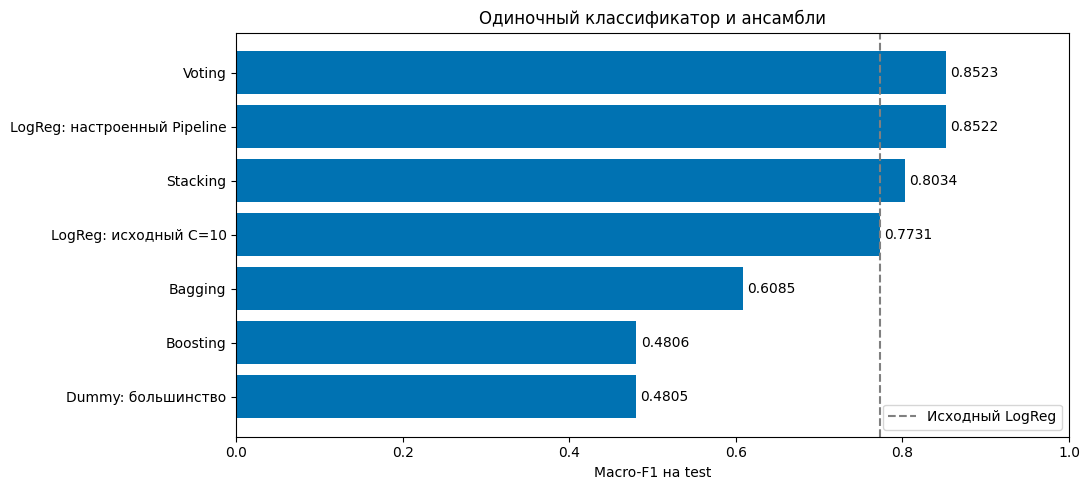

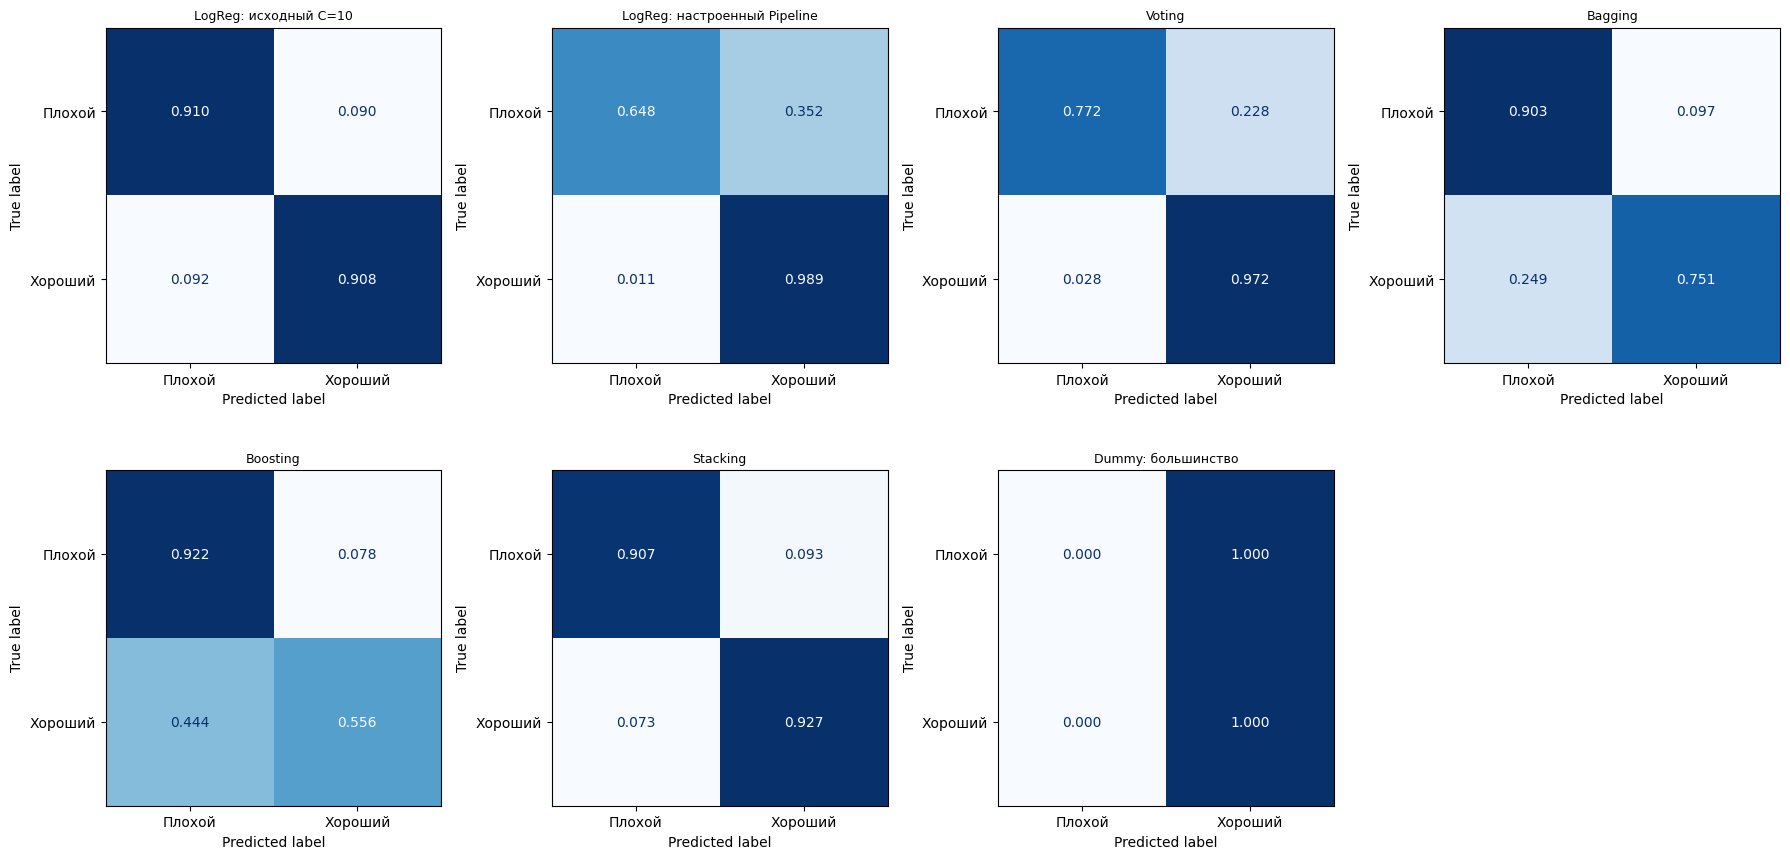

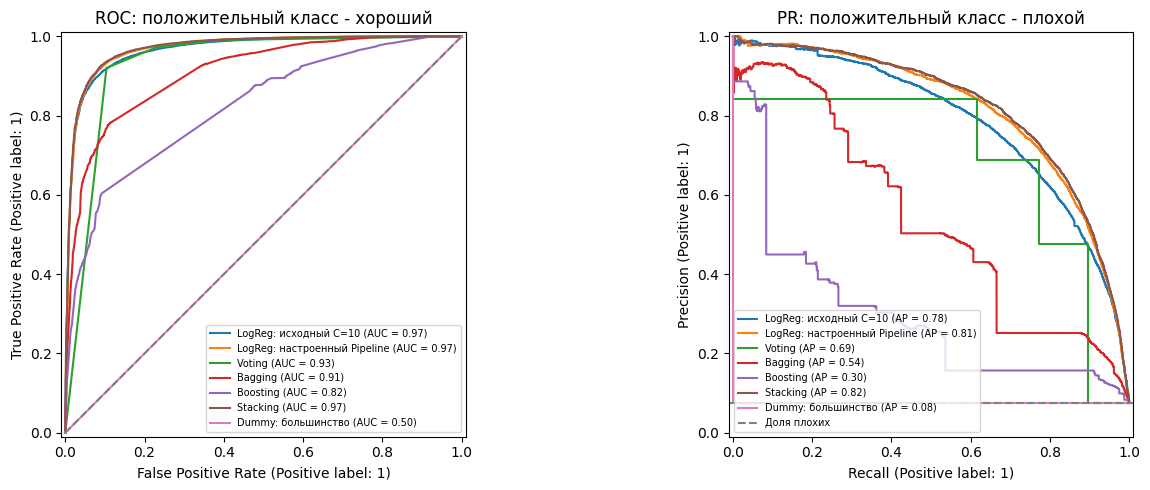

 LogReg: исходный C=10
               precision    recall  f1-score   support

 Плохой [0-3]    0.44546   0.90959   0.59804      7853
Хороший [4-5]    0.99197   0.90792   0.94808     96568

     accuracy                        0.90805    104421
    macro avg    0.71872   0.90875   0.77306    104421
 weighted avg    0.95087   0.90805   0.92176    104421

 LogReg: настроенный Pipeline
               precision    recall  f1-score   support

 Плохой [0-3]    0.82104   0.64791   0.72427      7853
Хороший [4-5]    0.97185   0.98852   0.98011     96568

     accuracy                        0.96290    104421
    macro avg    0.89645   0.81821   0.85219    104421
 weighted avg    0.96051   0.96290   0.96087    104421

 Voting
               precision    recall  f1-score   support

 Плохой [0-3]    0.68923   0.77155   0.72807      7853
Хороший [4-5]    0.98124   0.97171   0.97645     96568

     accuracy                        0.95666    104421
    macro avg    0.83523   0.87163   0.85226    104

In [43]:
plot_table_7 = comparison_7.sort_values(METRIC_7)
fig, ax = plt.subplots(figsize=(11, 5))
bars = ax.barh(plot_table_7.method, plot_table_7[METRIC_7], color=OKABE[0])
ax.bar_label(bars, fmt="%.4f", padding=3)
ax.axvline(original_f1_7, linestyle="--", color="gray", label="Исходный LogReg")
ax.set(xlabel="Macro-F1 на test", xlim=(0, 1), title="Одиночный классификатор и ансамбли")
ax.legend(); plt.tight_layout(); plt.show()

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
for ax, name in zip(axes.ravel(), final_models_7):
    ConfusionMatrixDisplay.from_predictions(y_test_7, TEST_PRED_7[name], labels=[0, 1],
        display_labels=["Плохой", "Хороший"], normalize="true", ax=ax,
        cmap="Blues", values_format=".3f", colorbar=False)
    ax.set_title(name, fontsize=9)
for ax in axes.ravel()[len(final_models_7):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for name, score in TEST_SCORE_7.items():
    if score is not None:
        RocCurveDisplay.from_predictions(y_test_7, score, name=name, ax=axes[0])
        PrecisionRecallDisplay.from_predictions(1-y_test_7, -score, name=name, ax=axes[1])
axes[0].plot([0, 1], [0, 1], "--", color="gray")
axes[0].set_title("ROC: положительный класс - хороший")
axes[1].axhline((y_test_7 == 0).mean(), linestyle="--", color="gray", label="Доля плохих")
axes[1].set_title("PR: положительный класс - плохой")
for ax in axes:
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

for name, pred in TEST_PRED_7.items():
    print("="*70, "\n", name)
    print(classification_report(y_test_7, pred, labels=[0, 1], target_names=CLASS_NAMES_7,
                                digits=5, zero_division=0))


## 16. Парный bootstrap по товарам

Товары test ресемплируются целиком. Выводятся 95% интервалы изменения Macro-F1 относительно исходного и настроенного одиночного LogReg. Интервалы условны на обученных моделях и не учитывают повторное обучение и поиск параметров.


In [44]:
def macro_f1_from_counts_7(counts):
    # Последняя ось: TN, FP, FN, TP; positive=1.
    tn, fp, fn, tp = [counts[..., i] for i in range(4)]
    f0 = np.divide(2*tn, 2*tn+fp+fn, out=np.zeros_like(tn, dtype=float), where=(2*tn+fp+fn)>0)
    f1 = np.divide(2*tp, 2*tp+fp+fn, out=np.zeros_like(tp, dtype=float), where=(2*tp+fp+fn)>0)
    return (f0+f1)/2

product_codes_7, product_values_7 = pd.factorize(X_test_7["product_id"], sort=True)
method_order_7 = list(TEST_PRED_7)
group_counts_7 = np.zeros((len(product_values_7), len(method_order_7), 4), dtype=np.int64)
for j, name in enumerate(method_order_7):
    cell_codes = 2*y_test_7+TEST_PRED_7[name]
    np.add.at(group_counts_7[:, j, :], (product_codes_7, cell_codes), 1)
computed_7 = macro_f1_from_counts_7(group_counts_7.sum(axis=0))
expected_7 = [f1_score(y_test_7, TEST_PRED_7[name], average="macro") for name in method_order_7]
np.testing.assert_allclose(computed_7, expected_7, atol=1e-12)
bootstrap_f1_7 = np.empty((BOOTSTRAP_REPEATS_7, len(method_order_7)))
rng_boot_7 = np.random.default_rng(SEED_7)
for b in tqdm(range(BOOTSTRAP_REPEATS_7), desc="Bootstrap товаров"):
    sampled_products = rng_boot_7.integers(0, len(product_values_7), len(product_values_7))
    counts = group_counts_7[sampled_products].sum(axis=0)
    bootstrap_f1_7[b] = macro_f1_from_counts_7(counts)
original_index_7 = method_order_7.index("LogReg: исходный C=10")
tuned_index_7 = method_order_7.index("LogReg: настроенный Pipeline")
interval_rows_7 = []
for j, name in enumerate(method_order_7):
    d_original = bootstrap_f1_7[:, j]-bootstrap_f1_7[:, original_index_7]
    d_tuned = bootstrap_f1_7[:, j]-bootstrap_f1_7[:, tuned_index_7]
    interval_rows_7.append({"method": name,
        "delta_vs_original": computed_7[j]-computed_7[original_index_7],
        "ci_original_low": np.quantile(d_original, .025),
        "ci_original_high": np.quantile(d_original, .975),
        "delta_vs_tuned_single": computed_7[j]-computed_7[tuned_index_7],
        "ci_tuned_low": np.quantile(d_tuned, .025), "ci_tuned_high": np.quantile(d_tuned, .975)})
intervals_7 = pd.DataFrame(interval_rows_7)
display(intervals_7.round(5))
intervals_7.to_csv(OUTPUT_7 / "paired_product_bootstrap.csv", index=False)


Bootstrap товаров:   0%|          | 0/500 [00:00<?, ?it/s]

,method,delta_vs_original,ci_original_low,ci_original_high,delta_vs_tuned_single,ci_tuned_low,ci_tuned_high
0,LogReg: исходный C=10,0.00000,0.00000,0.00000,-0.07913,-0.08732,-0.07133
1,LogReg: настроенный Pipeline,0.07913,0.07133,0.08732,0.00000,0.00000,0.00000
2,Voting,0.07920,0.07394,0.08415,0.00007,-0.00468,0.00507
3,Bagging,-0.16461,-0.16940,-0.15988,-0.24374,-0.25169,-0.23557
4,Boosting,-0.29251,-0.30034,-0.28477,-0.37164,-0.37918,-0.36330
5,Stacking,0.03029,0.02690,0.03343,-0.04884,-0.05659,-0.04021
6,Dummy: большинство,-0.29260,-0.30164,-0.28190,-0.37173,-0.37847,-0.36358


## 17. Выводы по фактическим результатам

Отдельно оцениваются эффект настройки классификатора и эффект ансамблирования. Представление признаков, обработка и внешнее разделение во всех сравнениях фиксированы. Улучшение качества ансамблем не гарантируется, а ухудшение само по себе не устанавливает переобучение.


In [ ]:
indexed_7 = comparison_7.set_index("method")
ci_indexed_7 = intervals_7.set_index("method")
ensemble_names_7 = list(ENSEMBLE_FIXED_OPTIONS_7)
best_test_ensemble_7 = indexed_7.loc[ensemble_names_7, METRIC_7].idxmax()
chosen_7 = indexed_7.loc[SELECTED_METHOD_7]
best_ensemble_row_7 = indexed_7.loc[best_test_ensemble_7]
text_lines_7 = [
    f"1. Использован прежний target_2 и тот же групповой сплит: {len(y_train_7):,} отзывов train, "
    f"{len(y_val_7):,} validation и {len(y_test_7):,} test. Доля плохих отзывов test - {(y_test_7 == 0).mean():.2%}. "
    "Macro-F1 одинаково учитывает оба класса; высокая accuracy большинства не заменяет качество редкого класса.",
    f"2. Исходный LogReg (C=10): test Macro-F1 = {original_f1_7:.5f}. "
    f"LogReg после настройки классификатора: {tuned_f1_7:.5f}; изменение {tuned_f1_7-original_f1_7:+.5f}. "
    "Настраивались признаки (max_features/min_df), шаг снижения размерности (passthrough / SelectKBest(chi2)) и параметры LogReg по validation.",
    f"3. До test по validation выбран {SELECTED_METHOD_7}. Его test Macro-F1 = {chosen_7[METRIC_7]:.5f}, "
    f"precision плохого класса = {chosen_7['precision_0']:.5f}, recall = {chosen_7['recall_0']:.5f}. "
    "Precision характеризует достоверность найденных плохих отзывов, recall - полноту их обнаружения.",
    f"4. При описательном ранжировании test лучший ансамбль - {best_test_ensemble_7}: "
    f"Macro-F1 = {best_ensemble_row_7[METRIC_7]:.5f}. Это не меняет предварительный выбор по validation."
]
for kind in ensemble_names_7:
    row, ci = indexed_7.loc[kind], ci_indexed_7.loc[kind]
    description = "выше" if row[METRIC_7] > tuned_f1_7 else "ниже" if row[METRIC_7] < tuned_f1_7 else "равен"
    uncertainty = ("интервал целиком выше нуля" if ci.ci_tuned_low > 0 else
                   "интервал целиком ниже нуля" if ci.ci_tuned_high < 0 else "интервал включает ноль")
    text_lines_7.append(f"- {kind}: Macro-F1 = {row[METRIC_7]:.5f}; изменение относительно исходного "
        f"{row['delta_vs_original']:+.5f}, относительно настроенного одиночного Pipeline "
        f"{row['delta_vs_tuned_single']:+.5f}. Результат {description} настроенного одиночного; "
        f"95% парный bootstrap-интервал дополнительного прироста "
        f"[{ci.ci_tuned_low:+.5f}; {ci.ci_tuned_high:+.5f}], {uncertainty}.")
sig_better_7 = [k for k in ensemble_names_7 if ci_indexed_7.loc[k, "ci_tuned_low"] > 0]
tie_7 = [k for k in ensemble_names_7
         if ci_indexed_7.loc[k, "ci_tuned_low"] <= 0 <= ci_indexed_7.loc[k, "ci_tuned_high"]]
if sig_better_7:
    _msg6 = ("Статистически значимо (bootstrap-интервал выше нуля) превзошли настроенную одиночную модель: "
             + ", ".join(sig_better_7) + ".")
elif tie_7:
    _msg6 = ("Ни один ансамбль не превзошёл настроенную одиночную модель значимо: лучший — " + best_test_ensemble_7
             + " — лишь сравнялся с ней (прирост в пределах шума, bootstrap-интервал включает ноль), остальные ниже.")
else:
    _msg6 = "В проверенных конфигурациях ансамбли не улучшили Macro-F1 относительно настроенной одиночной модели."
text_lines_7.append("6. " + _msg6)
text_lines_7.append("7. Предобработка до разделения сохранена из ЛР 5-6, включая округление рейтингов и фильтрацию корпуса. "
    "Поиск — 45 trial Optuna по векторизации, снижению размерности и классификатору; финальные модели дообучены на train+val; test ранее использовался в ЛР 5-6. Выводы описывают результаты этого протокола, "
    "а не гарантируют превосходство на новых источниках отзывов.")
_tuned_ci_7 = ci_indexed_7.loc["LogReg: настроенный Pipeline"]
text_lines_7.append(
    f"8. Настройка пайплайна дала значимый прирост к исходному LogReg: {_tuned_ci_7['delta_vs_original']:+.5f} "
    f"(95% bootstrap [{_tuned_ci_7['ci_original_low']:+.5f}; {_tuned_ci_7['ci_original_high']:+.5f}], интервал выше нуля). "
    "Выиграли больший словарь (max_features), passthrough (без снижения размерности) и параметры LogReg.")
text_lines_7.append(
    f"9. Нюанс по редкому классу: настроенная одиночная модель максимизирует Macro-F1 ценой полноты — "
    f"recall плохих = {indexed_7.loc['LogReg: настроенный Pipeline','recall_0']:.3f}; "
    f"Voting при той же Macro-F1 ловит больше (recall = {indexed_7.loc['Voting','recall_0']:.3f}), "
    f"Stacking — ещё больше (recall = {indexed_7.loc['Stacking','recall_0']:.3f}). "
    "Если цель — находить максимум плохих отзывов, предпочтительнее Voting/Stacking.")
text_lines_7.append(
    "10. Снижение размерности проверено и отклонено числами: в поиске победил passthrough, "
    "SelectKBest(chi2) не превзошёл полный TF-IDF, а TruncatedSVD (диагностика) удерживает лишь ~45-64% дисперсии "
    "и в прошлых прогонах давал ниже Macro-F1.")
conclusions_7 = "\n\n".join(text_lines_7)
display(Markdown(conclusions_7))
(OUTPUT_7 / "conclusions.md").write_text(conclusions_7, encoding="utf-8")


## 18. Сохранение и прогнозирование

Сохраняются модели, обученные только на train, и таблицы поиска/validation/test. Для новых отзывов применяется прежняя функция preprocess. В новом ядре перед загрузкой joblib выполните исходные определения preprocess и определение FixedPreprocessor7 из этого ноутбука.


In [46]:
def detach_memory_7(estimator):
    result = copy.deepcopy(estimator)
    # get_params(deep=True) включает Pipeline внутри Voting/Stacking.
    memory_params = {key: None for key in result.get_params(deep=True)
                     if key == "memory" or key.endswith("__memory")}
    if memory_params:
        result.set_params(**memory_params)
    if isinstance(result, (VotingClassifier, StackingClassifier)):
        result.estimators_ = [detach_memory_7(est) for est in result.estimators_]
        if hasattr(result, "named_estimators_"):
            for (name, _), fitted in zip(result.estimators, result.estimators_):
                result.named_estimators_[name] = fitted
    return result

saved_models_7 = {name: detach_memory_7(model) for name, model in final_models_7.items()}
joblib.dump({"models": saved_models_7, "selected_by_validation": SELECTED_METHOD_7,
    "class_names": CLASS_NAMES_7, "best_classifier_params": BEST_CLASSIFIER_PARAMS_7,
    "fixed_ensemble_options": ENSEMBLE_FIXED_OPTIONS_7}, OUTPUT_7 / "trained_models.joblib", compress=3)
run_info_7 = {"seed": SEED_7, "source_notebook": "perekrestok_dz2_hw56_(6)_(1) (1).ipynb",
    "n_train": len(TR_7), "n_validation": len(VA_7), "n_test": len(TE_7),
    "optuna_trials": len(study_7.trials), "train_val_merged": True,
    "best_features": BEST_FEATURE_7, "reduction": BEST_FEATURE_7["reduce_kind"],
    "selected_by_validation": SELECTED_METHOD_7, "best_classifier_params": BEST_CLASSIFIER_PARAMS_7,
    "fixed_ensemble_options": ENSEMBLE_FIXED_OPTIONS_7, "sklearn_version": sklearn.__version__,
    "python_version": platform.python_version()}
(OUTPUT_7 / "run_info.json").write_text(json.dumps(run_info_7, ensure_ascii=False, indent=2), encoding="utf-8")
new_reviews_7 = ["Очень вкусный и свежий продукт, буду покупать еще",
                 "Продукт испорчен, неприятный запах, больше не куплю"]
selected_model_7 = saved_models_7[SELECTED_METHOD_7]
new_predictions_7 = selected_model_7.predict(new_reviews_7)
display(pd.DataFrame({"Отзыв": new_reviews_7,
    "Предсказанный класс": [CLASS_NAMES_7[int(label)] for label in new_predictions_7]}))
print("Результаты сохранены:", OUTPUT_7.resolve())


,Отзыв,Предсказанный класс
0,"Очень вкусный и свежий продукт, буду покупать еще",Хороший [4-5]
1,"Продукт испорчен, неприятный запах, больше не куплю",Плохой [0-3]


Результаты сохранены: /Users/polina/outputs_lr7_ml_only


## Источники новой части

- [Optuna Study](https://optuna.readthedocs.io/en/stable/reference/generated/optuna.study.Study.html).
- [LogisticRegression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html).
- [VotingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.VotingClassifier.html).
- [BaggingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.BaggingClassifier.html).
- [AdaBoostClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.AdaBoostClassifier.html).
- [StackingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingClassifier.html).
